In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt

In [3]:
dd=pd.read_csv('../dataset/dp_lms_student_analytics_dataset.csv')
dd.info()


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   StudentID             500 non-null    int64
 1   StudentName           500 non-null    str  
 2   Gender                500 non-null    str  
 3   Age                   500 non-null    int64
 4   City                  500 non-null    str  
 5   Course                500 non-null    str  
 6   Instructor            500 non-null    str  
 7   EnrollmentDate        500 non-null    str  
 8   Batch                 500 non-null    str  
 9   CourseFee             500 non-null    int64
 10  PaymentMethod         500 non-null    str  
 11  AttendancePercentage  500 non-null    int64
 12  AssignmentScore       500 non-null    int64
 13  QuizScore             500 non-null    int64
 14  FinalScore            500 non-null    int64
 15  CourseProgress        500 non-null    int64
 16  StudyHoursPerWeek  

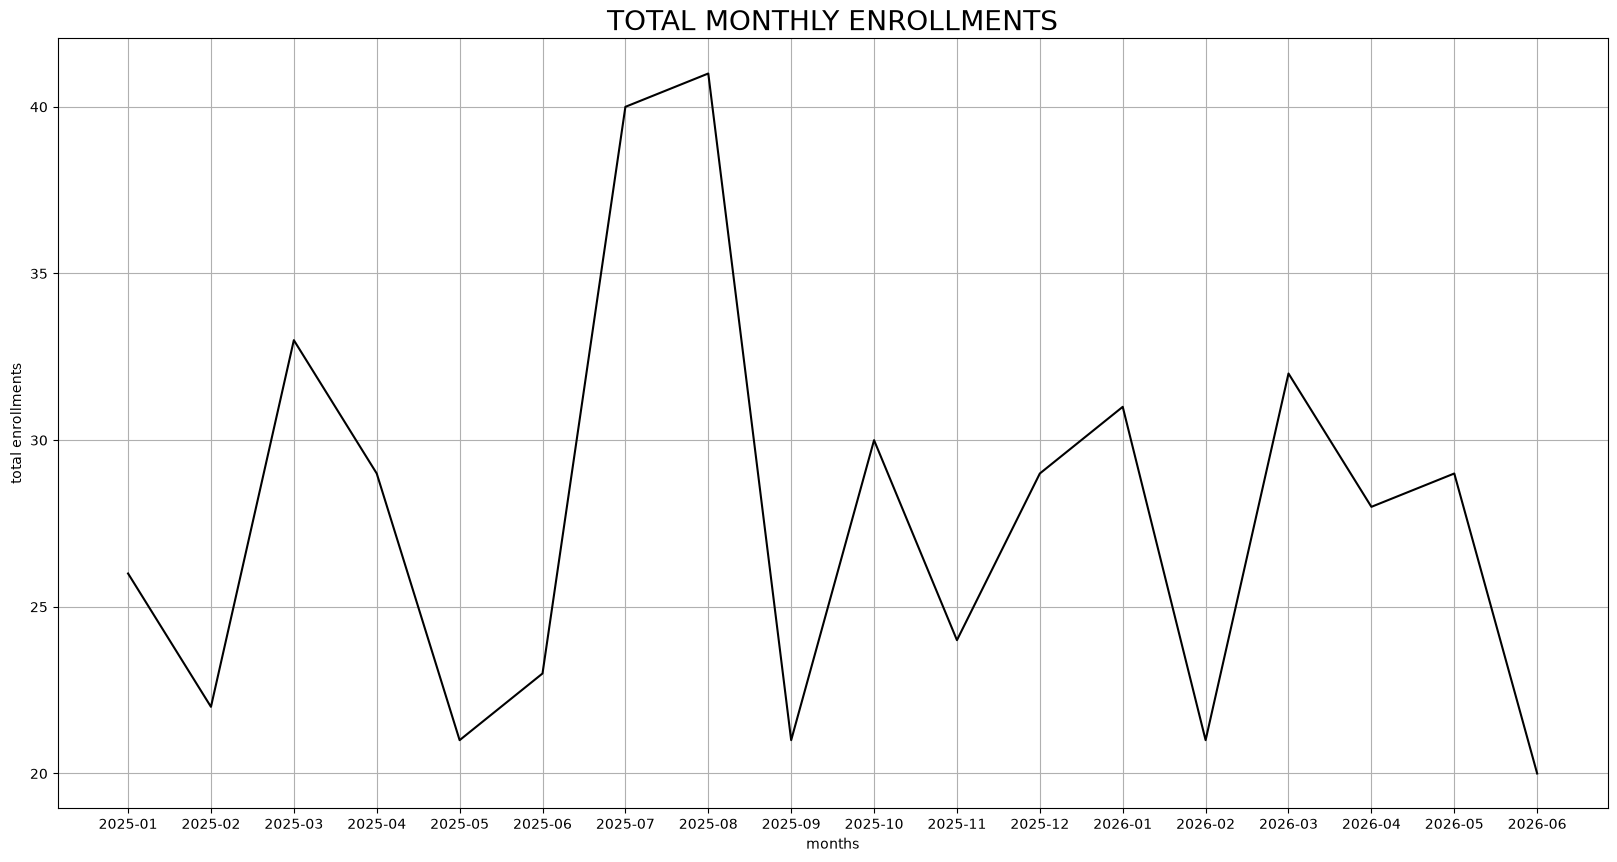

In [4]:
#1.1 monthly student enrollments
# this question alone took me 48minutes to understand and solve but i got it finally
dd["EnrollmentDate"] = pd.to_datetime(dd["EnrollmentDate"]) # convert date str value to datetime # yo hamile padethenam from lectures
#dd["EnrollmentDate"]
dd["Month"] = dd["EnrollmentDate"].dt.to_period("M") # month ma convert garem eg:2025-1
# new syntax for me , we didnot used .dt.month because different year pani xa
monthly_enroll = dd.groupby(dd['Month']).size() # group garem each similar value ra count garem
#monthly_enroll #la thik xa balla right 
plt.figure(figsize=(20,10)) # saguro bhayo
monthly_enroll.index= monthly_enroll.index.astype(str) # it didnot ran becuase yo ma chai plot garda float ma convert garna khojyo but it cannot convert so str banako
plt.plot(monthly_enroll.index,monthly_enroll.values,color='black') # this is normal
plt.xlabel('months',fontsize = 10)
plt.ylabel('total enrollments',fontsize= 10)
plt.title('TOTAL MONTHLY ENROLLMENTS',fontsize= 20)
plt.grid()

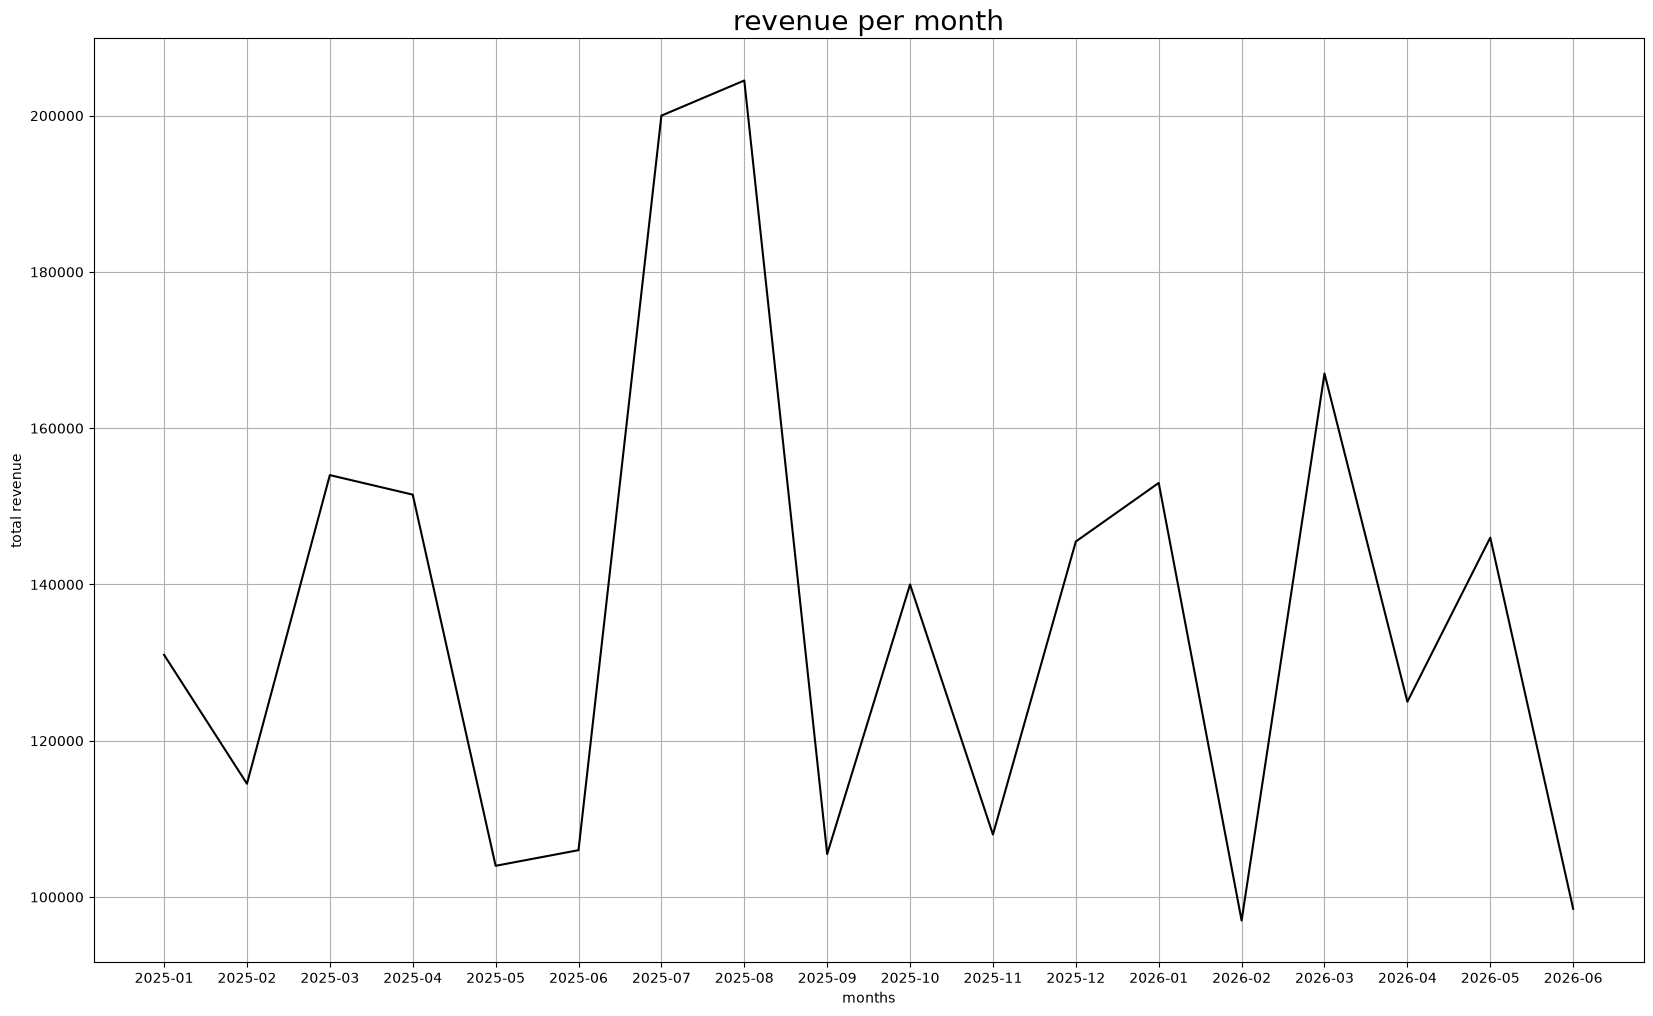

In [5]:
# 1.2monthly revenue trend  # same to same 
revenue=dd.groupby('Month')['Revenue'].sum()
plt.figure(figsize=(20,12))
plt.plot(revenue.index.astype(str),revenue.values,color='black')
plt.xlabel('months',fontsize = 10)
plt.ylabel('total revenue',fontsize= 10)
plt.title('revenue per month',fontsize= 20)
plt.grid()

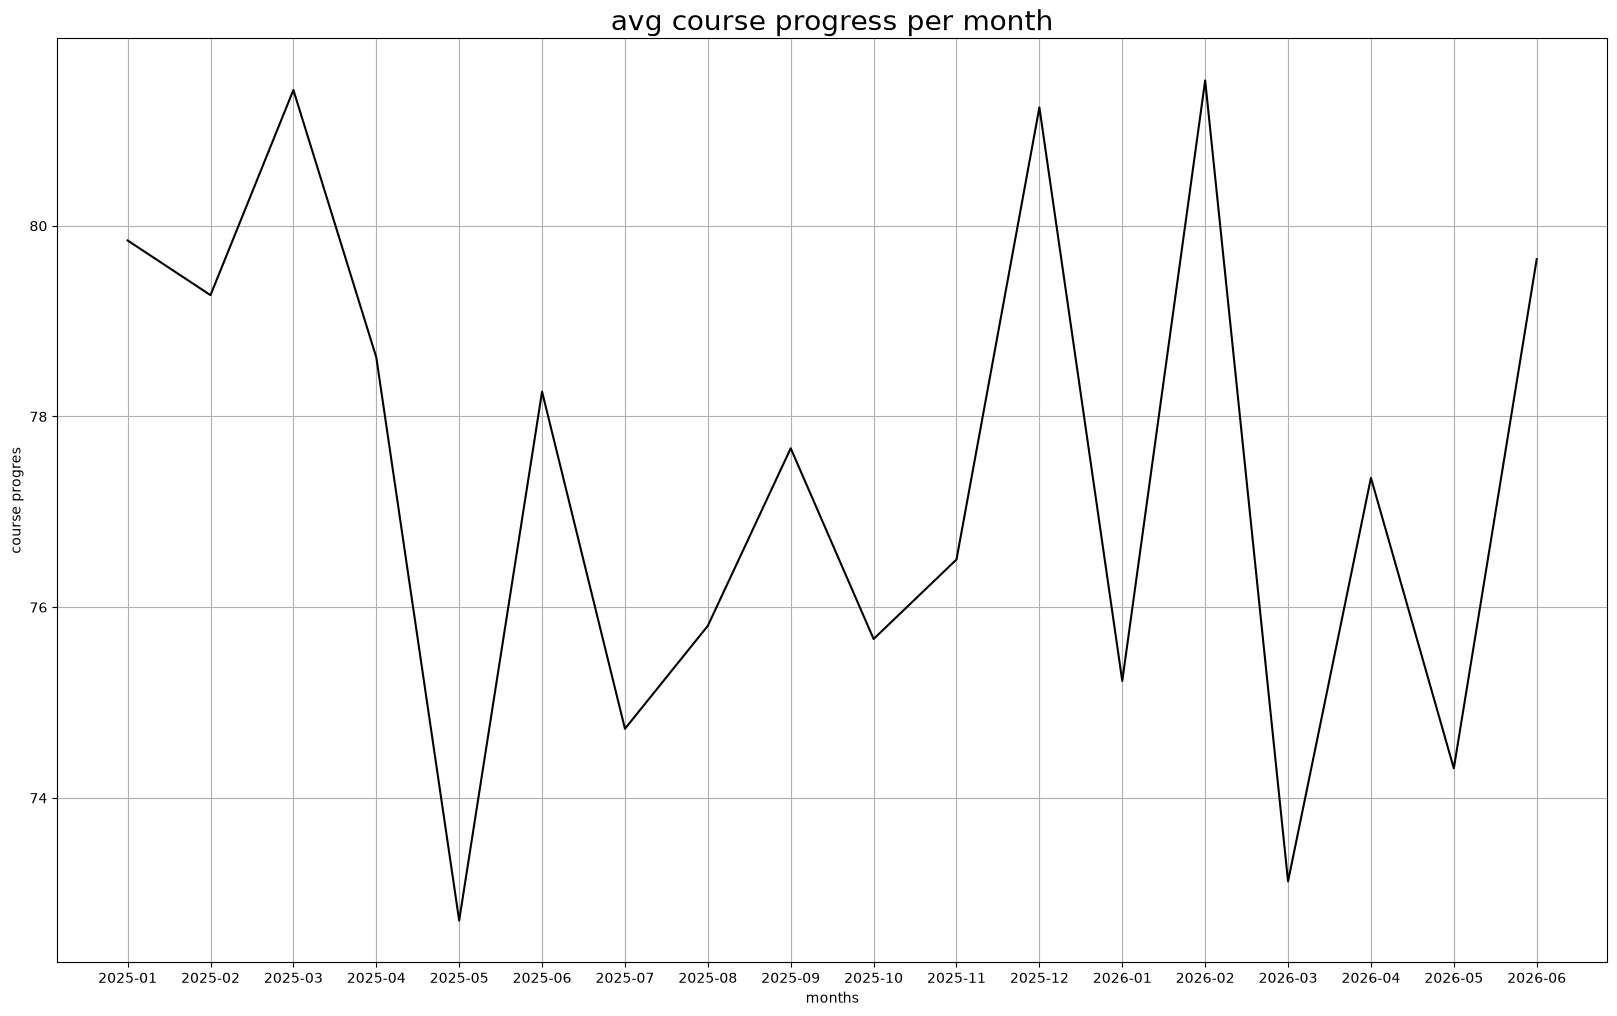

In [6]:
# 1.3 average course progress  by month
avg_progress = dd.groupby('Month')['CourseProgress'].mean()
plt.figure(figsize=(20,12))
avg_progress
plt.plot(avg_progress.index.astype(str),avg_progress.values,color='black')
plt.xlabel('months',fontsize = 10)
plt.ylabel('course progres',fontsize= 10)
plt.title('avg course progress per month',fontsize= 20)
plt.grid()

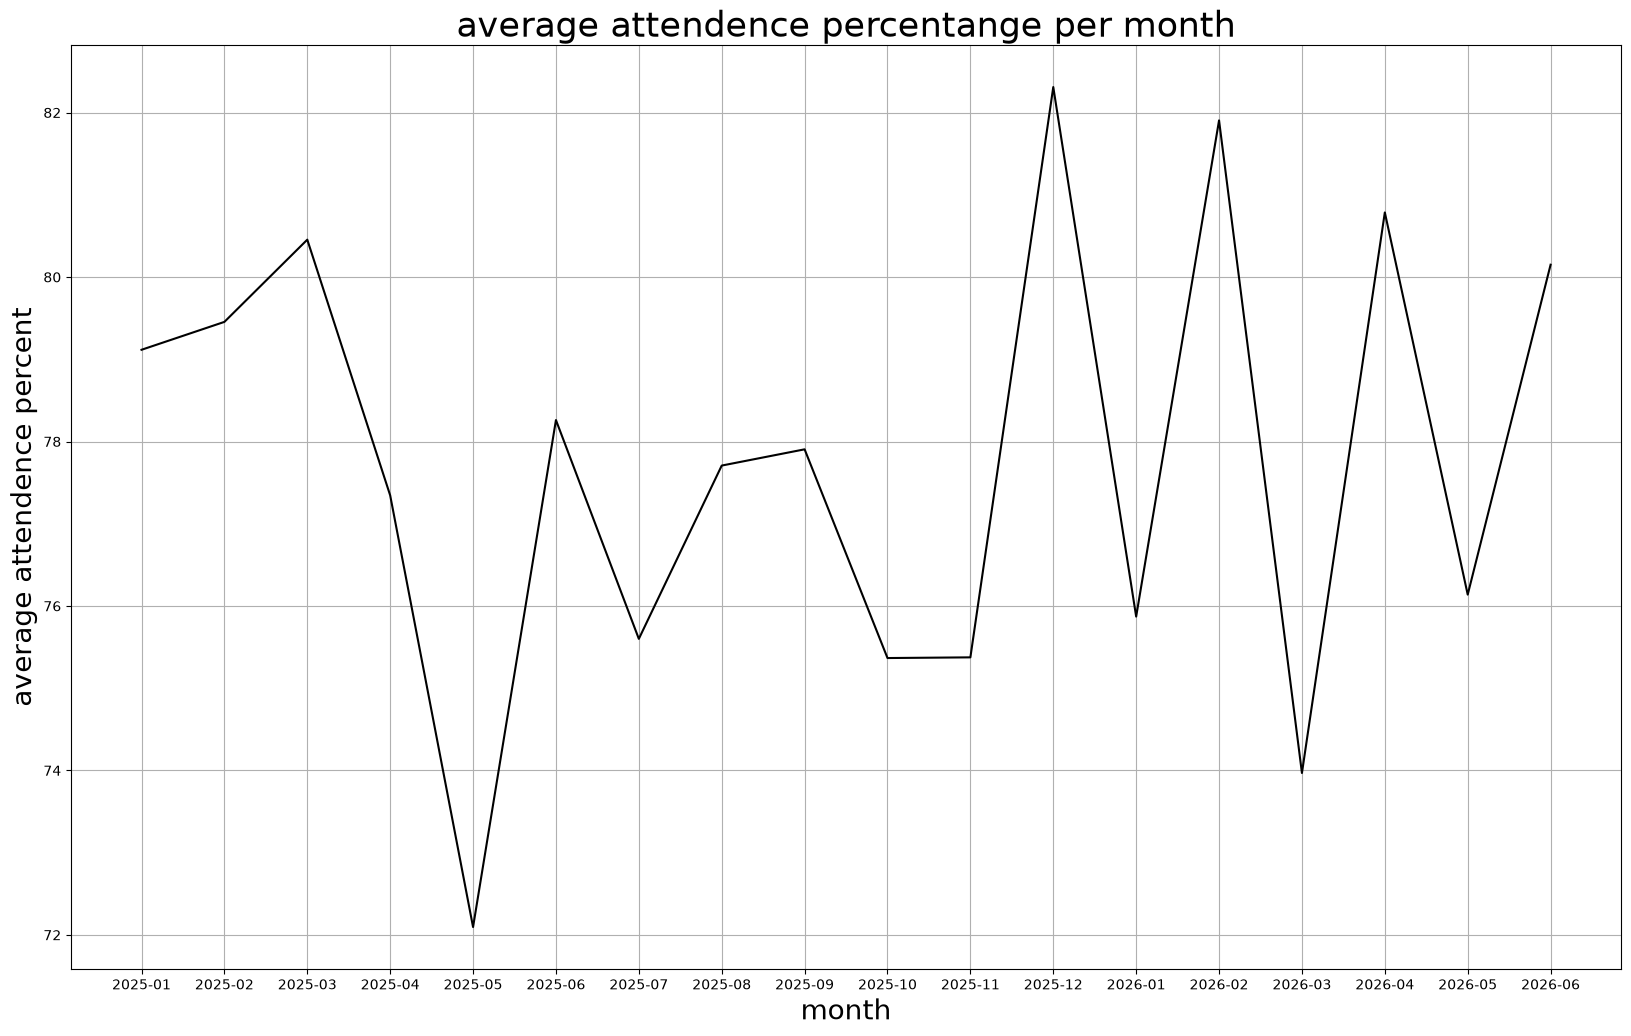

In [7]:
#1.4 average attendence percentange per month
avg_attendance =dd.groupby('Month')['AttendancePercentage'].mean()
plt.figure(figsize=(20,12))
plt.plot(avg_attendance.index.astype(str),avg_attendance.values,color='black')
plt.ylabel('average attendence percent',fontsize=20)
plt.xlabel('month',fontsize=20)
plt.title('average attendence percentange per month',fontsize=25)
plt.grid()

In [8]:
#2 bar charts

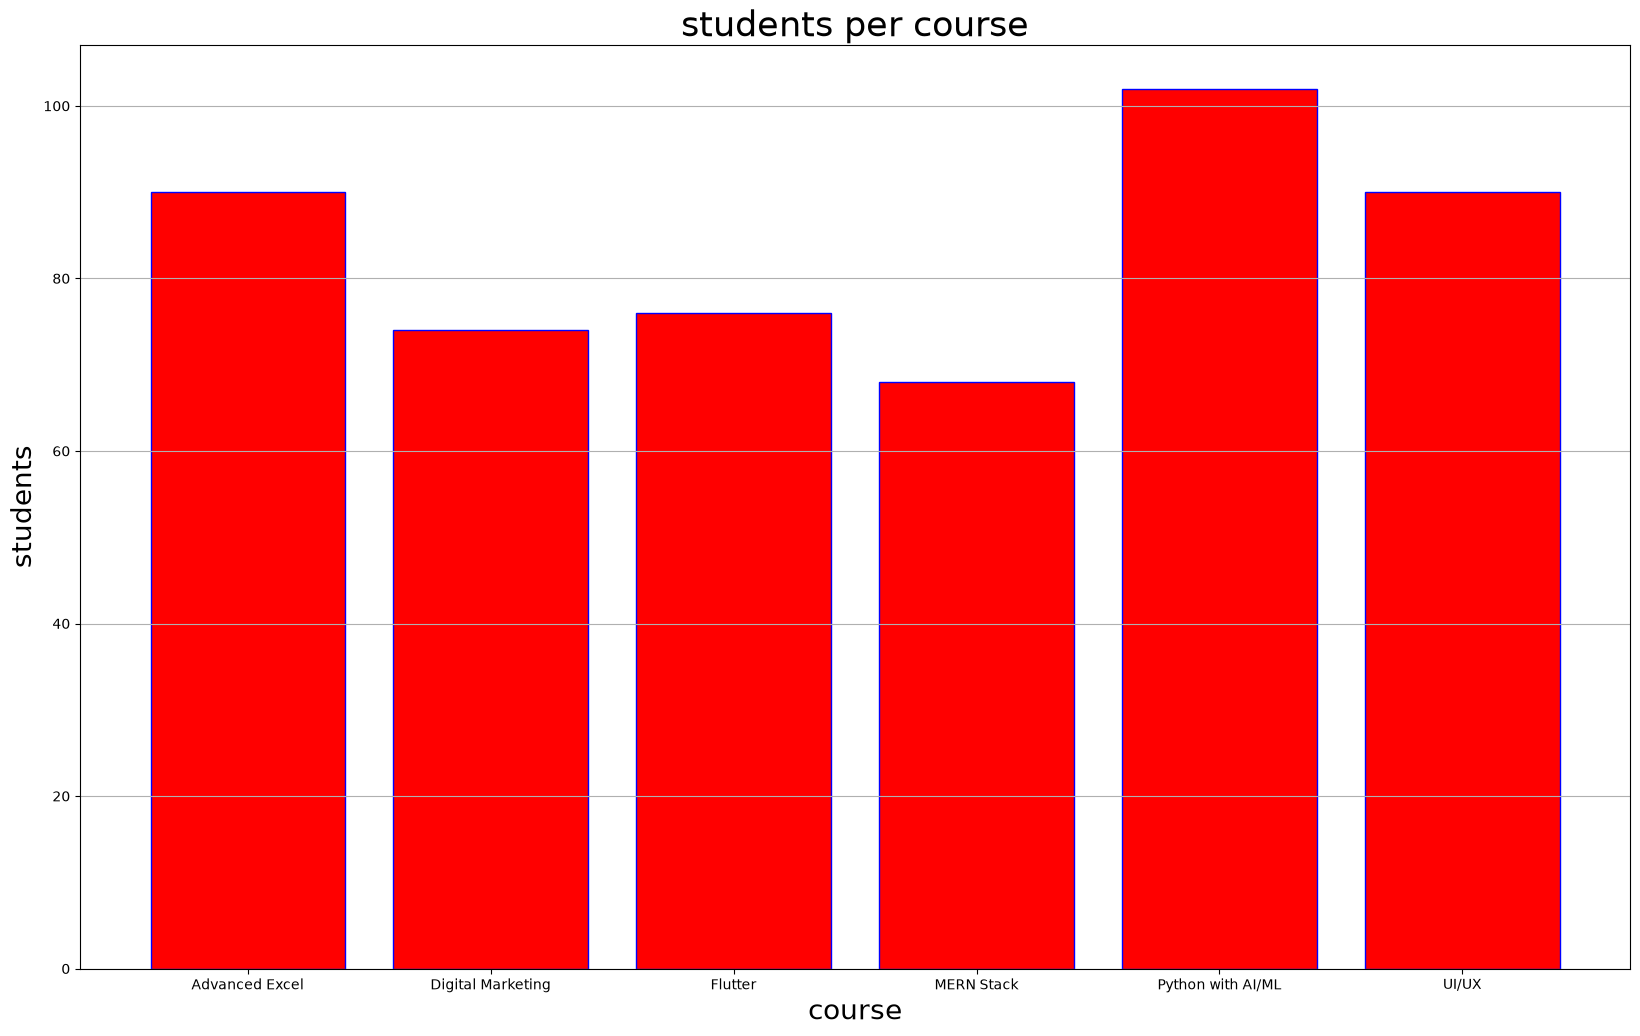

In [9]:
#2.1 students per course

plt.figure(figsize=(20,12))
student_course=dd.groupby('Course')['StudentName'].count()

plt.bar(student_course.index,student_course.values,color='red',edgecolor='blue')

plt.ylabel('students',fontsize=20)
plt.xlabel('course',fontsize=20)
plt.title('students per course',fontsize=25)
plt.grid(axis='y')


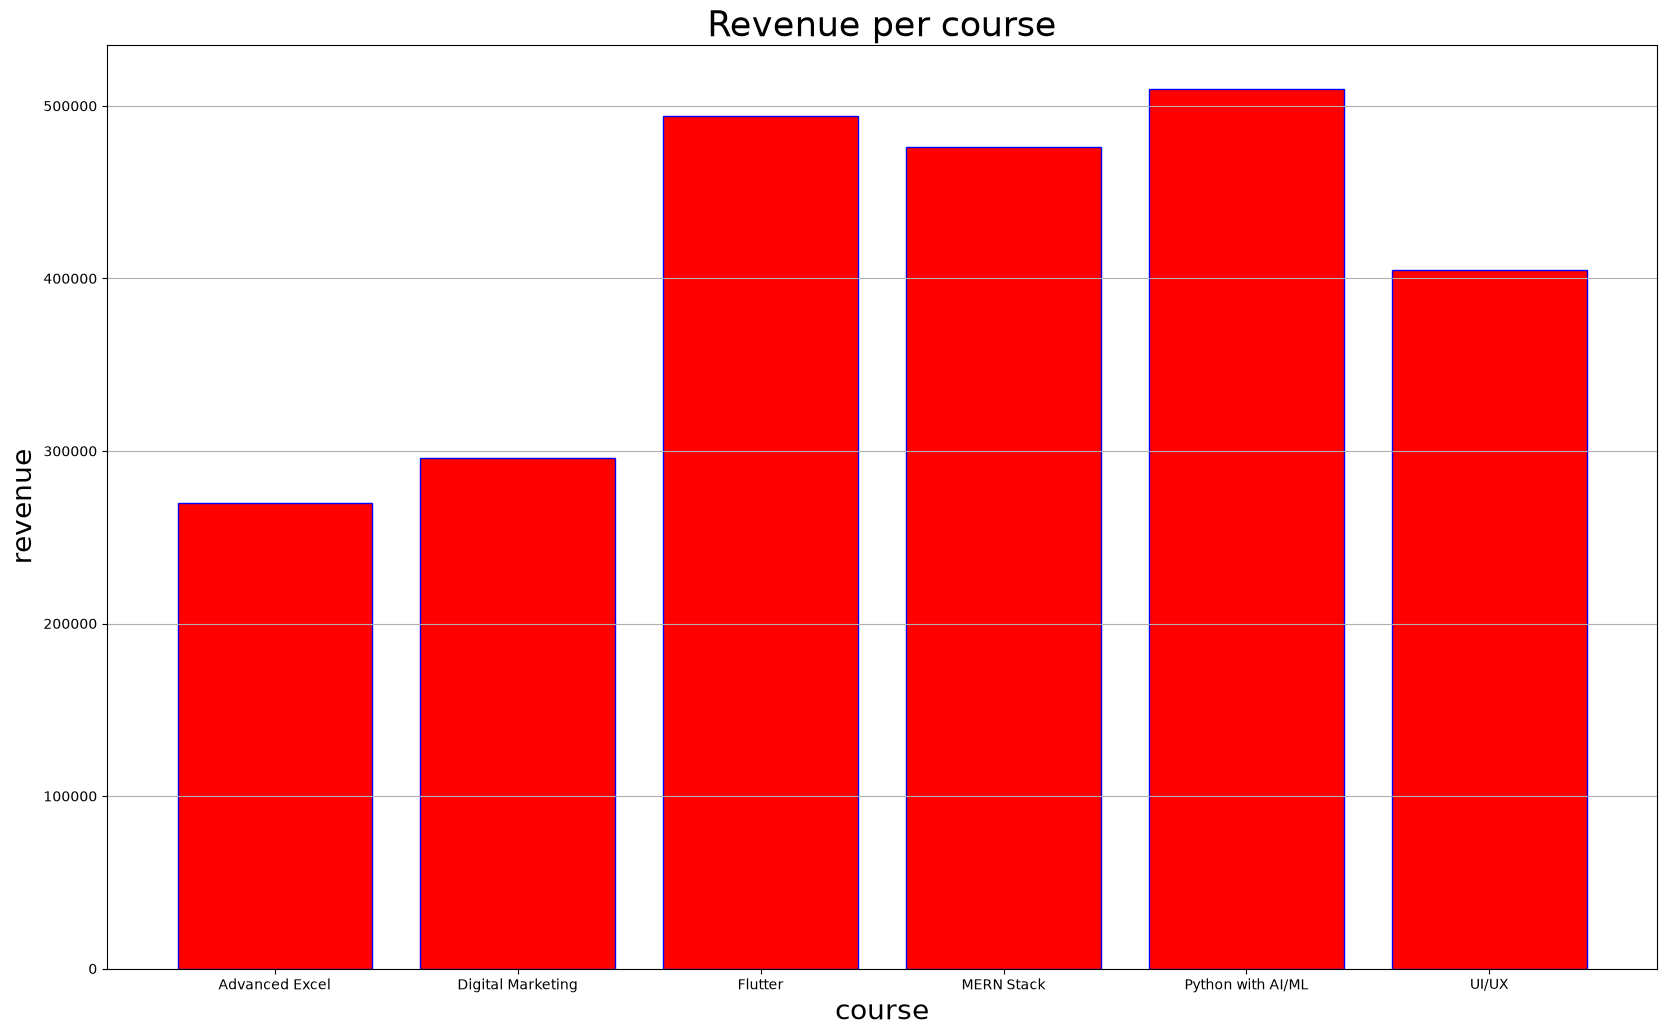

In [10]:
#2.2 revenue generated per each course
plt.figure(figsize=(20,12))
revenue=dd.groupby('Course')['Revenue'].sum()
plt.bar(revenue.index,revenue.values,color='red',edgecolor='blue')
plt.ylabel('revenue',fontsize=20)
plt.xlabel('course',fontsize=20)
plt.title('Revenue per course',fontsize=25)
plt.grid(axis='y')

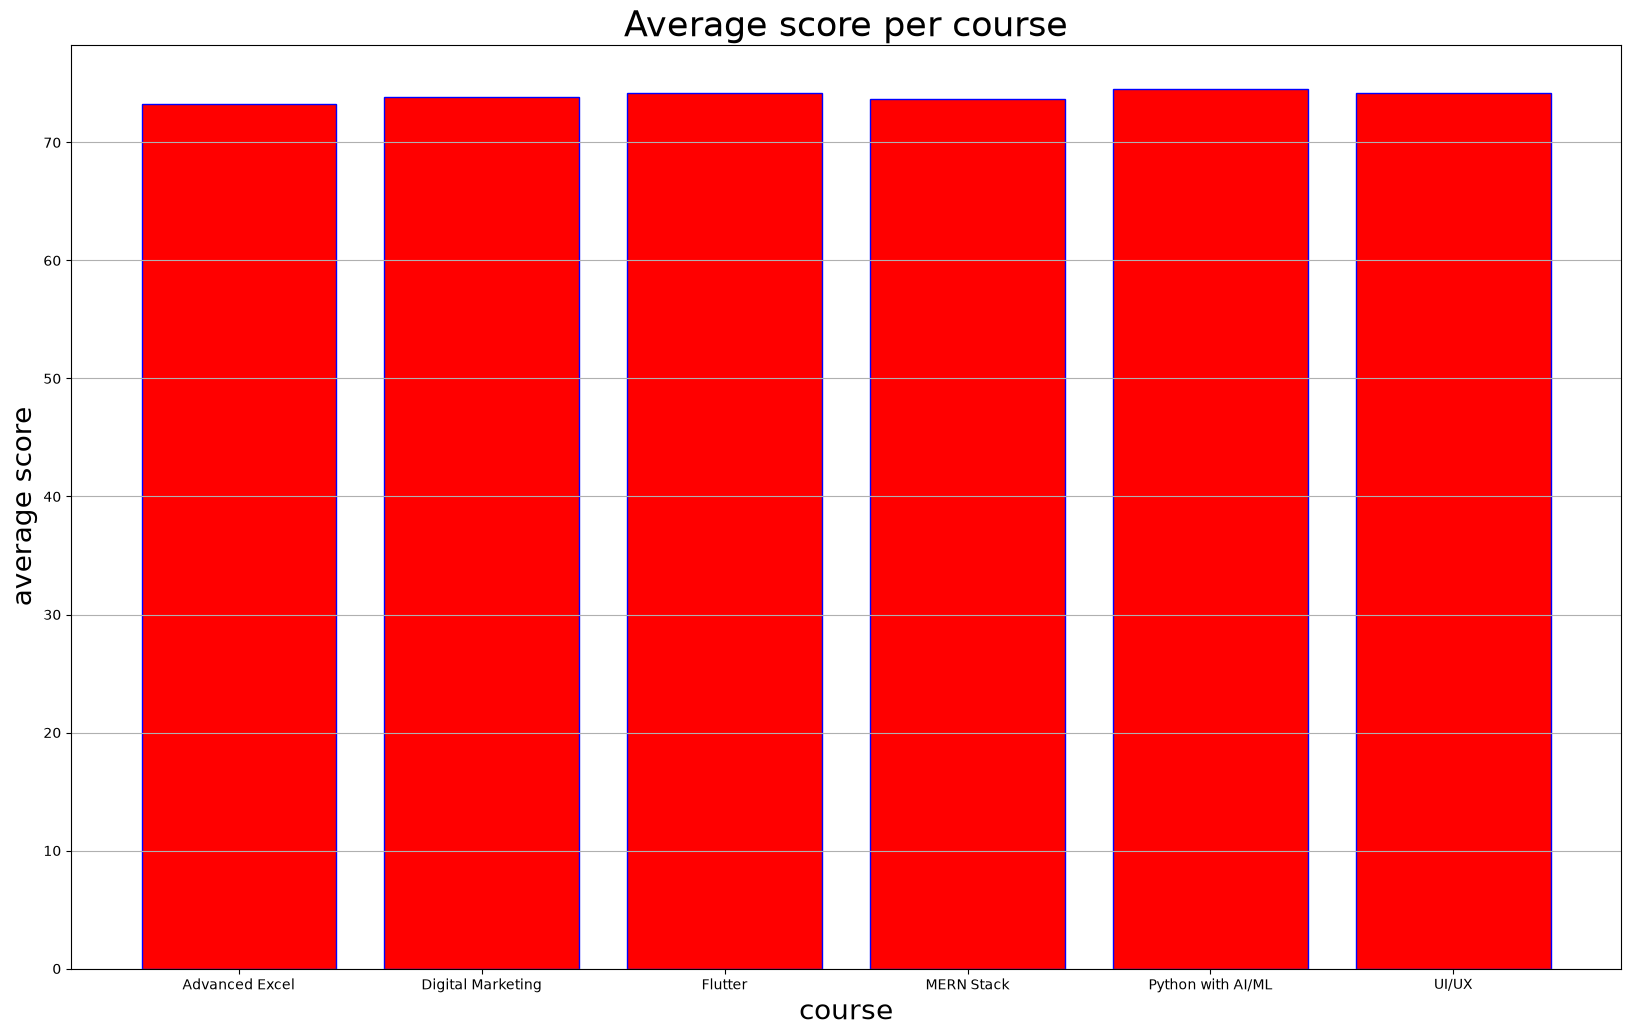

In [11]:
#2.3 average final score by course
plt.figure(figsize=(20,12))
final_score=dd.groupby('Course')['FinalScore'].mean()
plt.bar(final_score.index,final_score.values,color='red',edgecolor='blue')
plt.ylabel('average score',fontsize=20)
plt.xlabel('course',fontsize=20)
plt.title('Average score per course',fontsize=25)
plt.grid(axis='y')

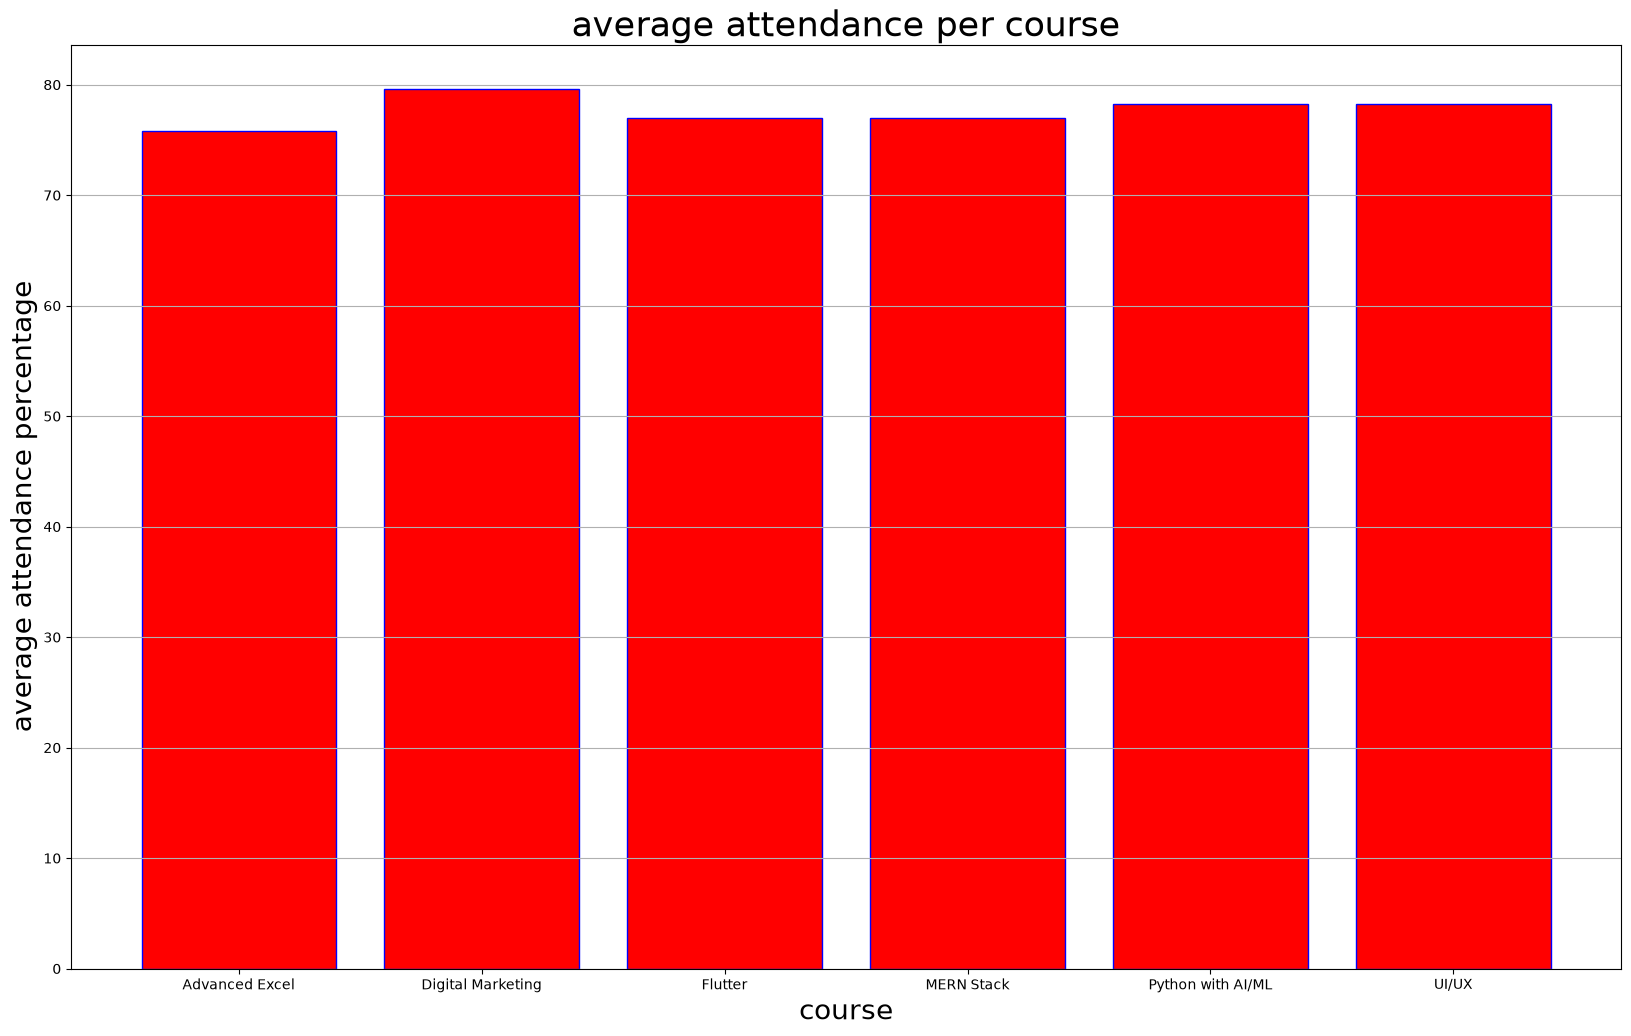

In [12]:
#2.4 average attendence percentage per course
plt.figure(figsize=(20,12))
avg_attendance=dd.groupby('Course')['AttendancePercentage'].mean()
plt.bar(avg_attendance.index,avg_attendance.values,color='red',edgecolor='blue')
plt.ylabel('average attendance percentage',fontsize=20)
plt.xlabel('course',fontsize=20)
plt.title('average attendance per course',fontsize=25)
plt.grid(axis='y')

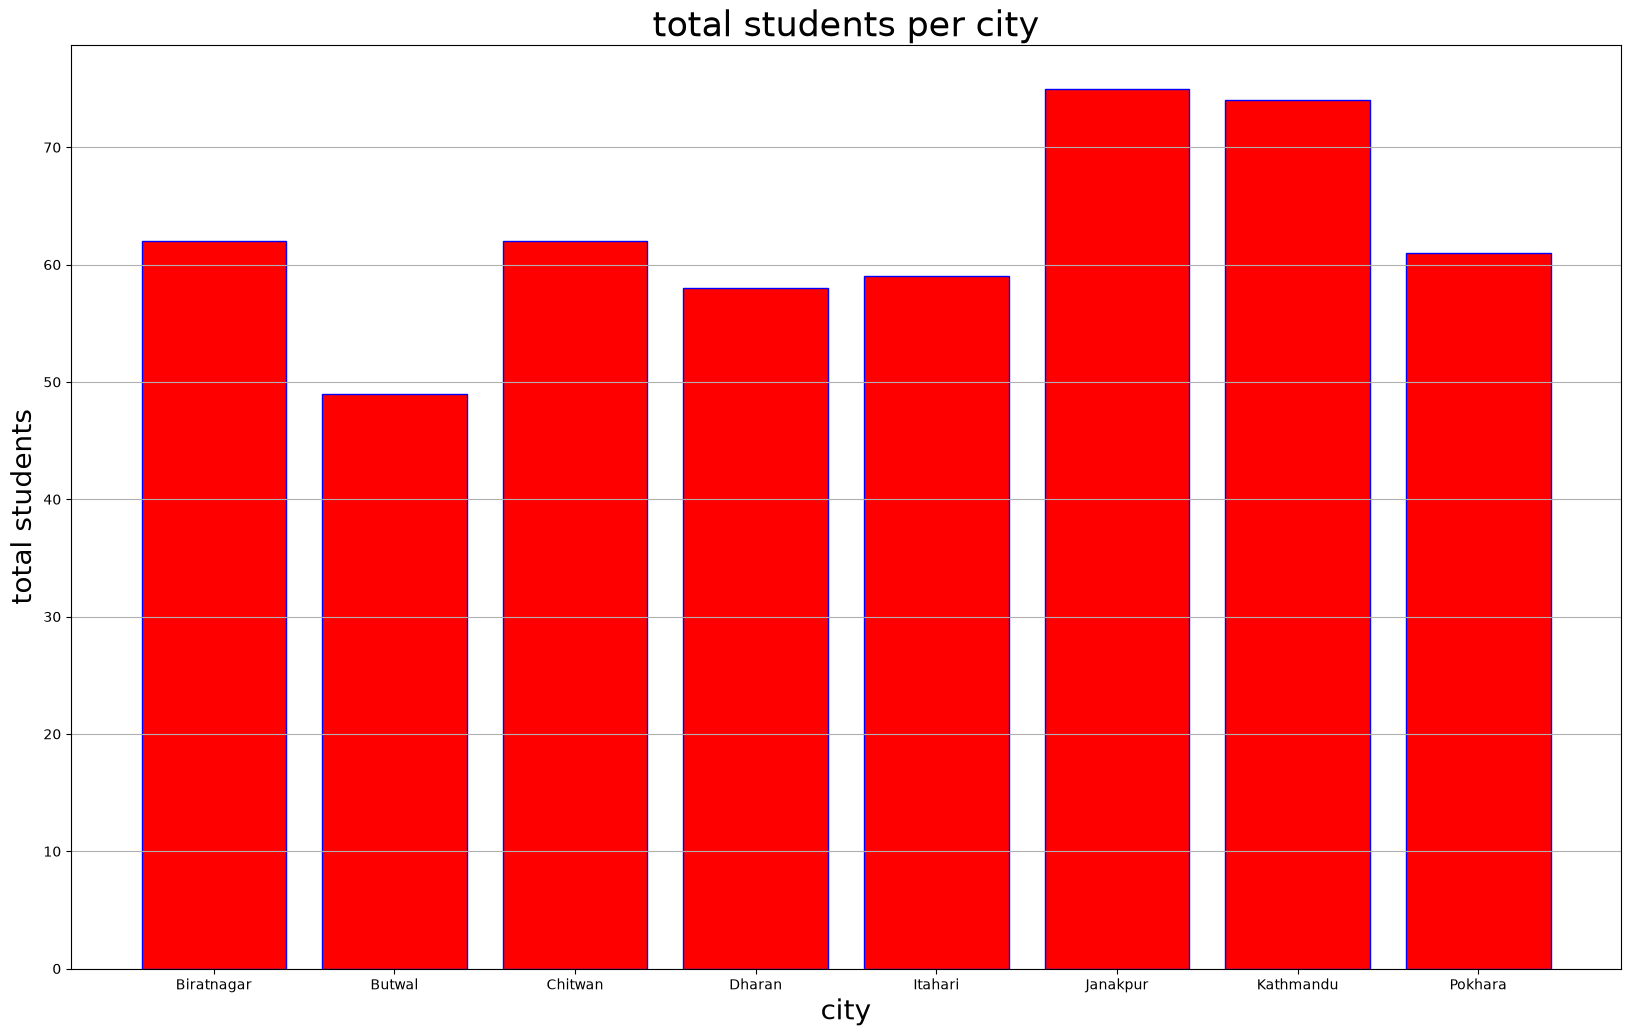

In [13]:
#2.5 number of students from each city
student=dd.groupby('City')['StudentName'].count()
plt.figure(figsize=(20,12))
plt.bar(student.index,student.values,color='red',edgecolor='blue')
plt.ylabel('total students',fontsize=20)
plt.xlabel('city',fontsize=20)
plt.title('total students per city',fontsize=25)
plt.grid(axis='y')

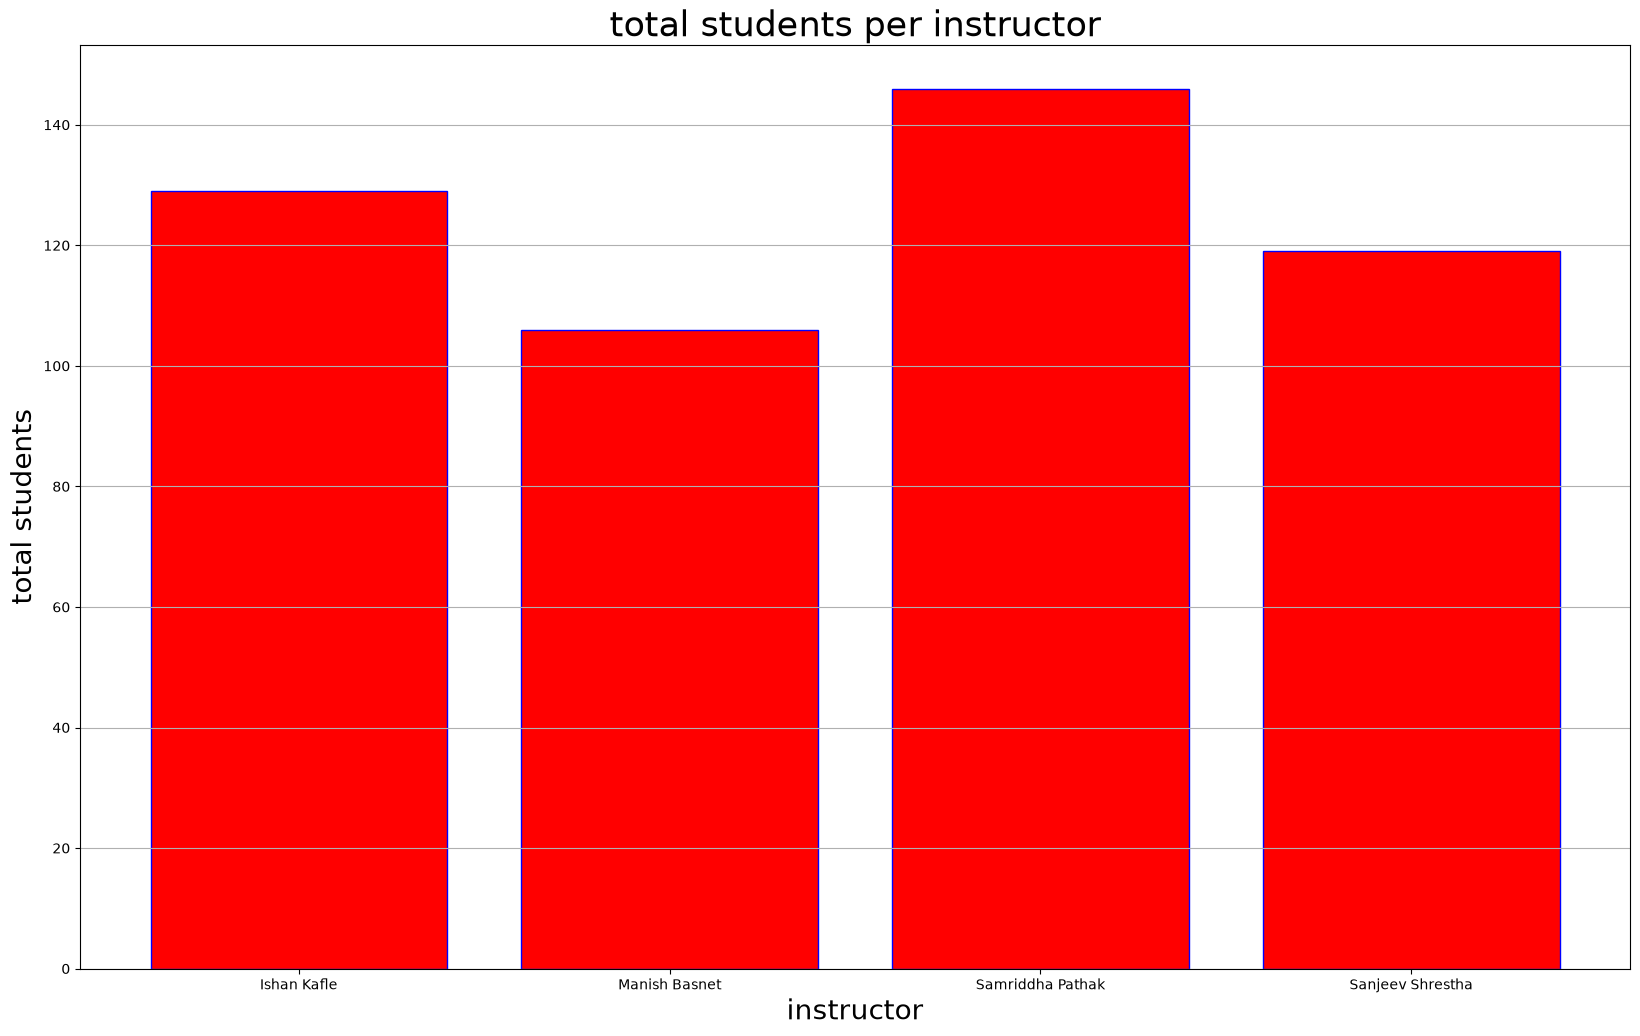

In [14]:
#2.6 number of students under each instructor
students=dd.groupby('Instructor')['StudentName'].count()
plt.figure(figsize=(20,12))
plt.bar(students.index,students.values,color='red',edgecolor='blue')
plt.ylabel('total students',fontsize=20)
plt.xlabel('instructor',fontsize=20)
plt.title('total students per instructor',fontsize=25)
plt.grid(axis='y')

In [15]:
#3 horizontal bar charts

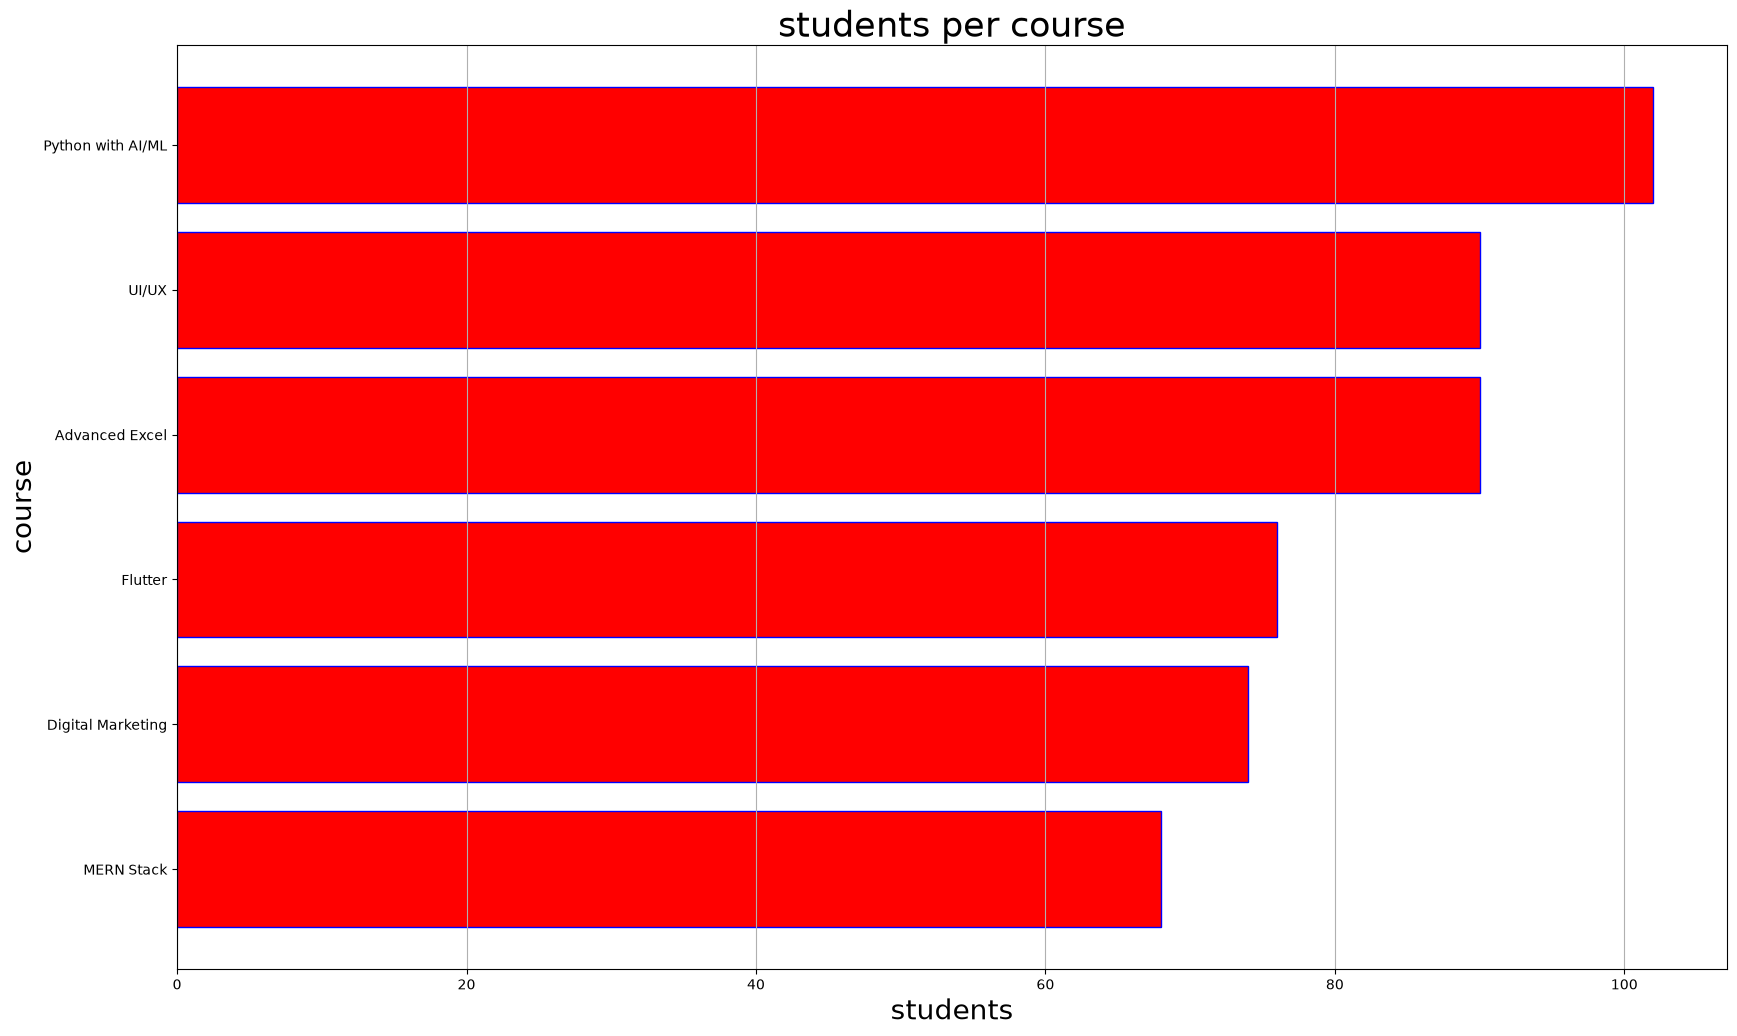

In [16]:
#3.1 top 10 courses by enrollments
# something that we didnot read in courses
#dd['Course'].unique()  only 6 ota course xa so all goes to top 10
student_course=dd.groupby('Course')['StudentName'].count().sort_values()
plt.figure(figsize=(20,12))
plt.barh(student_course.index,student_course.values,color='red',edgecolor='blue')
plt.ylabel('course',fontsize=20)
plt.xlabel('students',fontsize=20)
plt.title('students per course',fontsize=25)
plt.grid(axis='x')

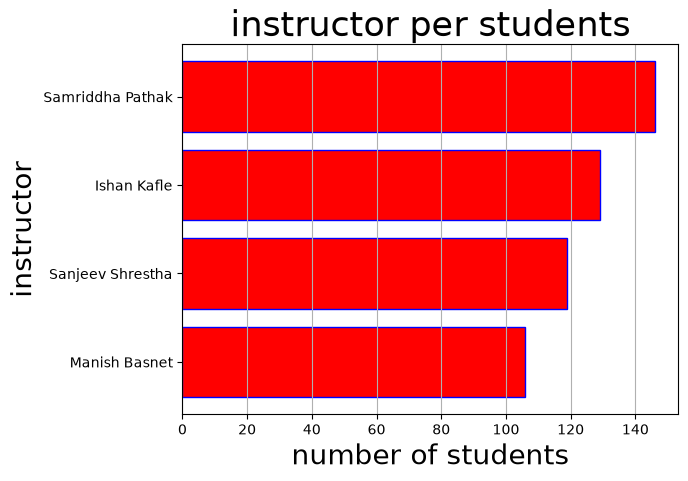

In [17]:
# 3.2 top 10 instructor by student enrollments
instructor=dd.groupby('Instructor')['StudentName'].count().sort_values()
plt.barh(instructor.index,instructor.values,color='red',edgecolor='blue')
plt.ylabel('instructor',fontsize=20)
plt.xlabel('number of students',fontsize=20)
plt.title('instructor per students',fontsize=25)
plt.grid(axis='x')

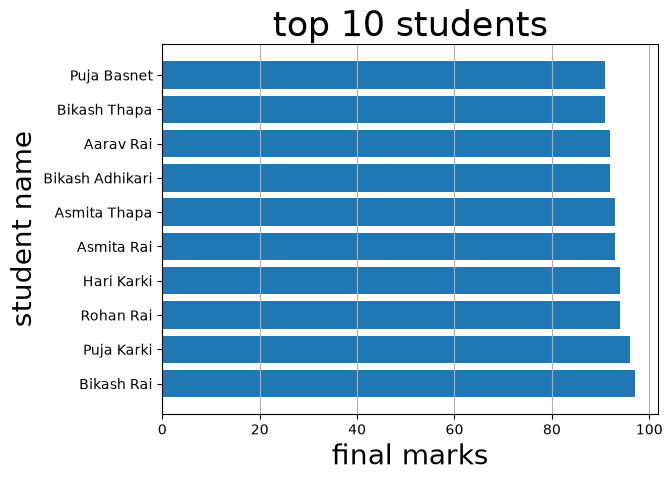

In [18]:
#3.3 top 10 students with the highest final scores
# little different question than above
top10 = dd.sort_values('FinalScore',ascending=False).head(10)
plt.barh(top10['StudentName'],top10['FinalScore'])
plt.ylabel('student name',fontsize=20)
plt.xlabel('final marks',fontsize=20)
plt.title('top 10 students',fontsize=25)
plt.grid(axis='x')

In [19]:
#4 histograms

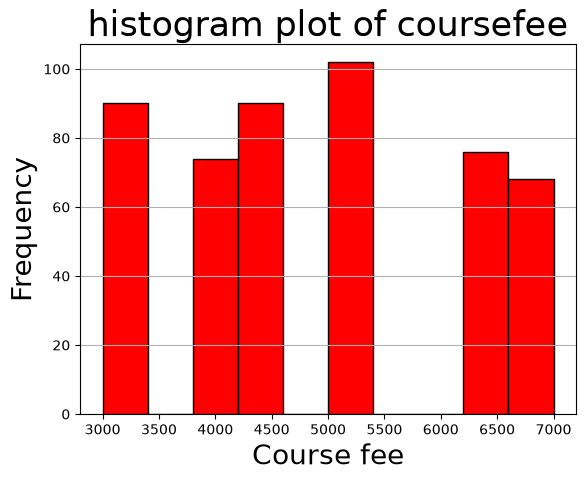

In [20]:
#4.1 histogram for course fee
plt.hist(dd['CourseFee'],color='red',edgecolor='black')
plt.ylabel('Frequency',fontsize=20)
plt.xlabel('Course fee',fontsize=20)
plt.title('histogram plot of coursefee',fontsize=25)
plt.grid(axis='y')

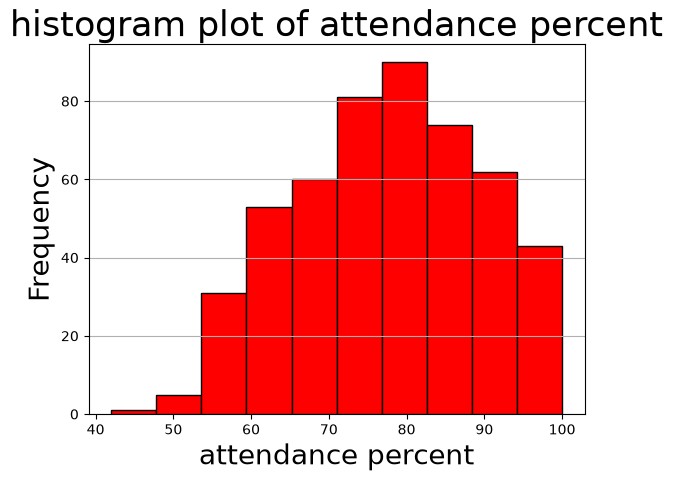

In [21]:
#4.2 attendance percent
plt.hist(dd['AttendancePercentage'],color='red',edgecolor='black')
plt.ylabel('Frequency',fontsize=20)
plt.xlabel('attendance percent',fontsize=20)
plt.title('histogram plot of attendance percent',fontsize=25)
plt.grid(axis='y')

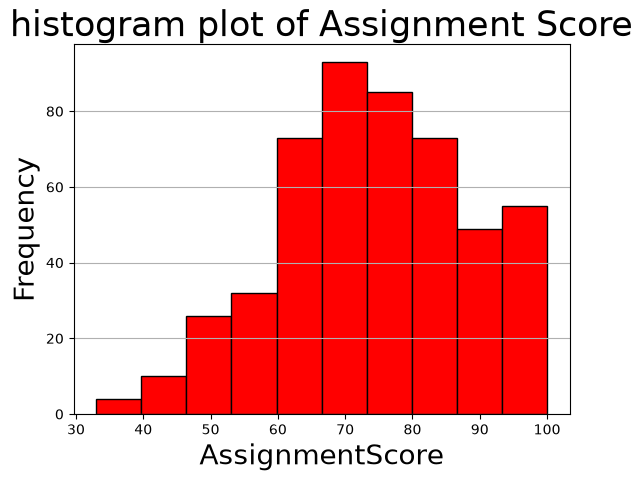

In [22]:
#4.3 assignment score
plt.hist(dd['AssignmentScore'],color='red',edgecolor='black')
plt.ylabel('Frequency',fontsize=20)
plt.xlabel('AssignmentScore',fontsize=20)
plt.title('histogram plot of Assignment Score',fontsize=25)
plt.grid(axis='y')

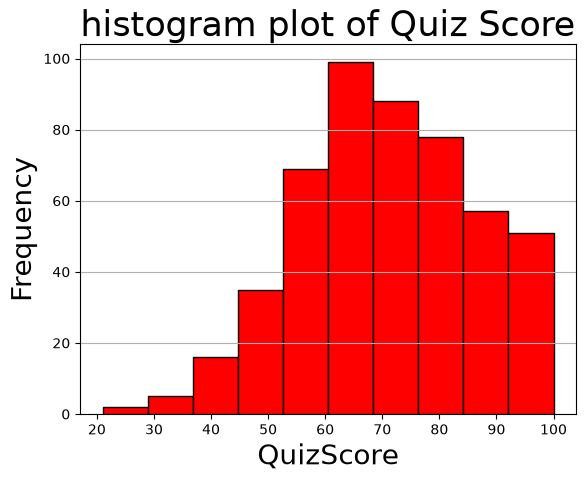

In [23]:
#4.4 quiz score
plt.hist(dd['QuizScore'],color='red',edgecolor='black')
plt.ylabel('Frequency',fontsize=20)
plt.xlabel('QuizScore',fontsize=20)
plt.title('histogram plot of Quiz Score',fontsize=25)
plt.grid(axis='y')

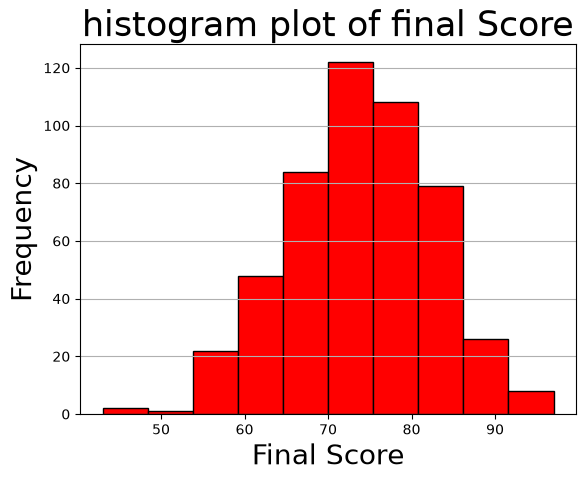

In [76]:
#4.5 Final score
plt.hist(dd['FinalScore'],color='red',edgecolor='black')
plt.ylabel('Frequency',fontsize=20)
plt.xlabel('Final Score',fontsize=20)
plt.title('histogram plot of final Score',fontsize=25)
plt.grid(axis='y')

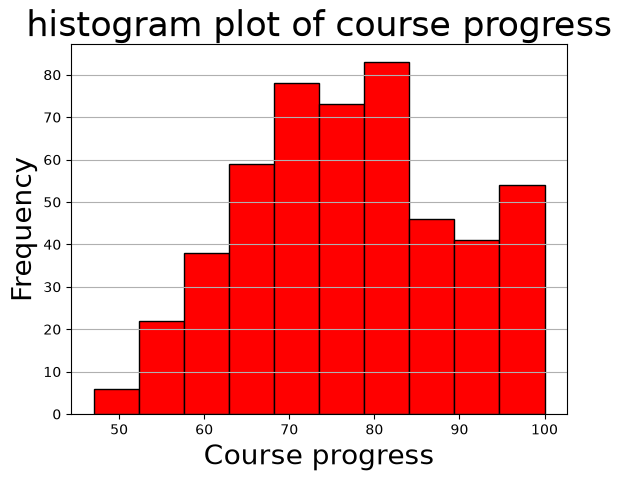

In [75]:
#4.6 course progress
plt.hist(dd['CourseProgress'],color='red',edgecolor='black')
plt.ylabel('Frequency',fontsize=20)
plt.xlabel('Course progress',fontsize=20)
plt.title('histogram plot of course progress',fontsize=25)
plt.grid(axis='y')

In [26]:
#5 pie charts


Text(0.5, 1.0, 'Piechart showing student distribution by course')

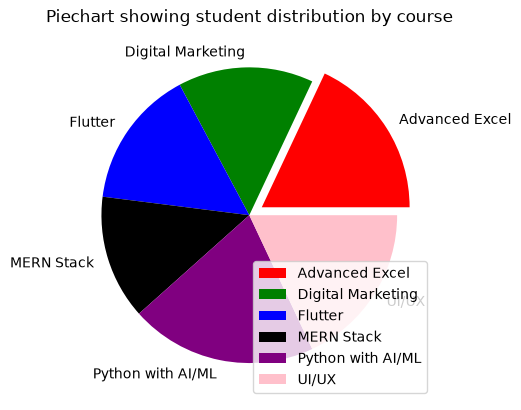

In [36]:
#5.1 student distribution by Course
student=dd.groupby('Course')['StudentName'].count()
plt.pie(student.values,labels=student.index,colors=['red','green','blue','black','purple','pink'],explode=[0.1,0,0,0,0,0])
plt.legend()
plt.title('Piechart showing student distribution by course')

Text(0.5, 1.0, 'Piechart showing student distribution by gender')

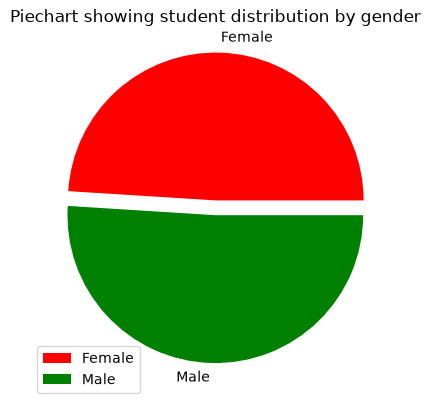

In [38]:
#5.2 student distribution by gender
student=dd.groupby('Gender')['StudentName'].count()
plt.pie(student.values,labels=student.index,colors=['red','green'],explode=[0.1,0])
plt.legend()
plt.title('Piechart showing student distribution by gender')

Text(0.5, 1.0, 'Piechart showing payment method distribution')

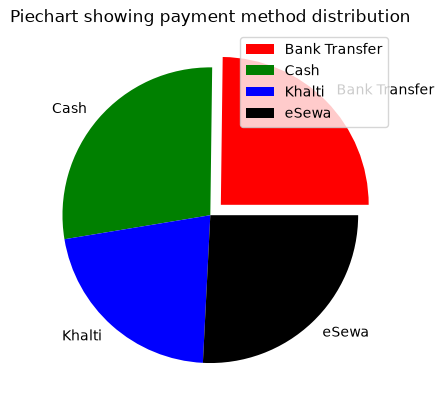

In [42]:
#5.3 payment method distribution
student=dd.groupby('PaymentMethod')['StudentName'].count()
plt.pie(student.values,labels=student.index,colors=['red','green','blue','black'],explode=[0.1,0,0,0])
plt.legend()
plt.title('Piechart showing payment method distribution')

Text(0.5, 1.0, 'Piechart showing student distribution by course')

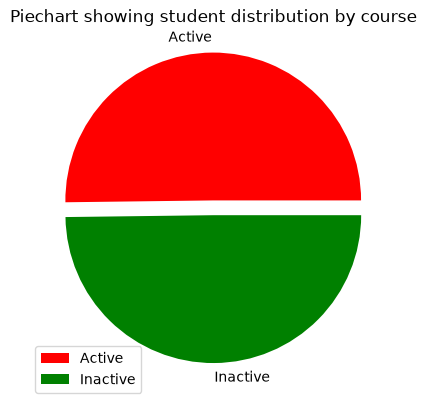

In [46]:
#5.4 student status distribution
student=dd.groupby('StudentStatus')['StudentName'].count()
plt.pie(student.values,labels=student.index,colors=['red','green','blue','black','purple','pink'],explode=[0.1,0])
plt.legend()
plt.title('Piechart showing student distribution by status')

Text(0.5, 1.0, 'Piechart showing certificates status')

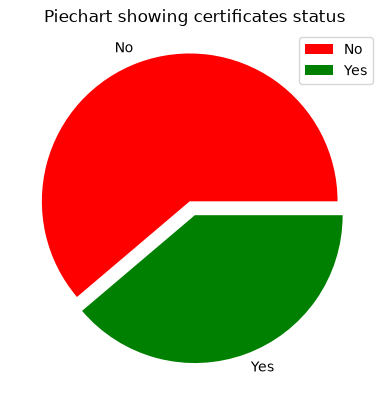

In [48]:
#5.5 certificates issued vs not isssued
student=dd.groupby('CertificateIssued')['StudentName'].count()
plt.pie(student.values,labels=student.index,colors=['red','green','blue','black','purple','pink'],explode=[0.1,0])
plt.legend()
plt.title('Piechart showing certificates status')

In [ ]:
#scatter plot

Text(0, 0.5, 'Final Score')

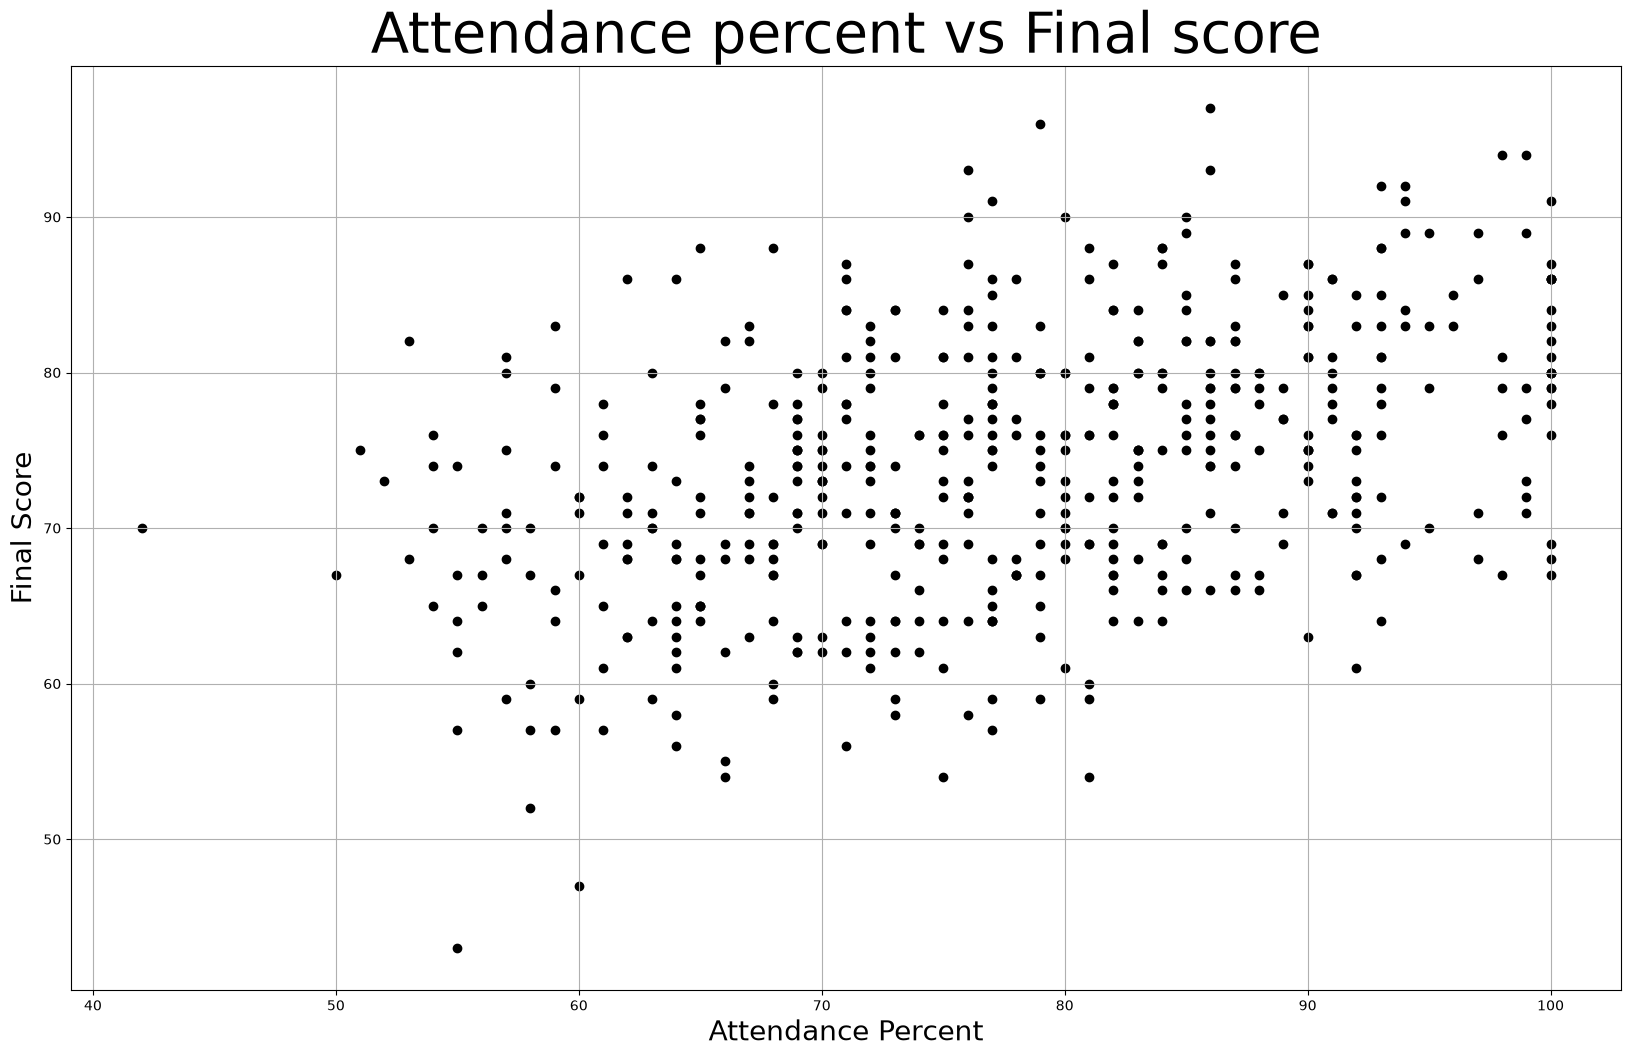

In [62]:
#6.1 attendance percent vs final score
plt.figure(figsize=(20,12))
plt.scatter(dd['AttendancePercentage'],dd['FinalScore'],color='black')

plt.grid()
plt.title('Attendance percent vs Final score',fontsize=40)
plt.xlabel('Attendance Percent',fontsize=20)
plt.ylabel('Final Score',fontsize=20)


Text(0, 0.5, 'Final Score')

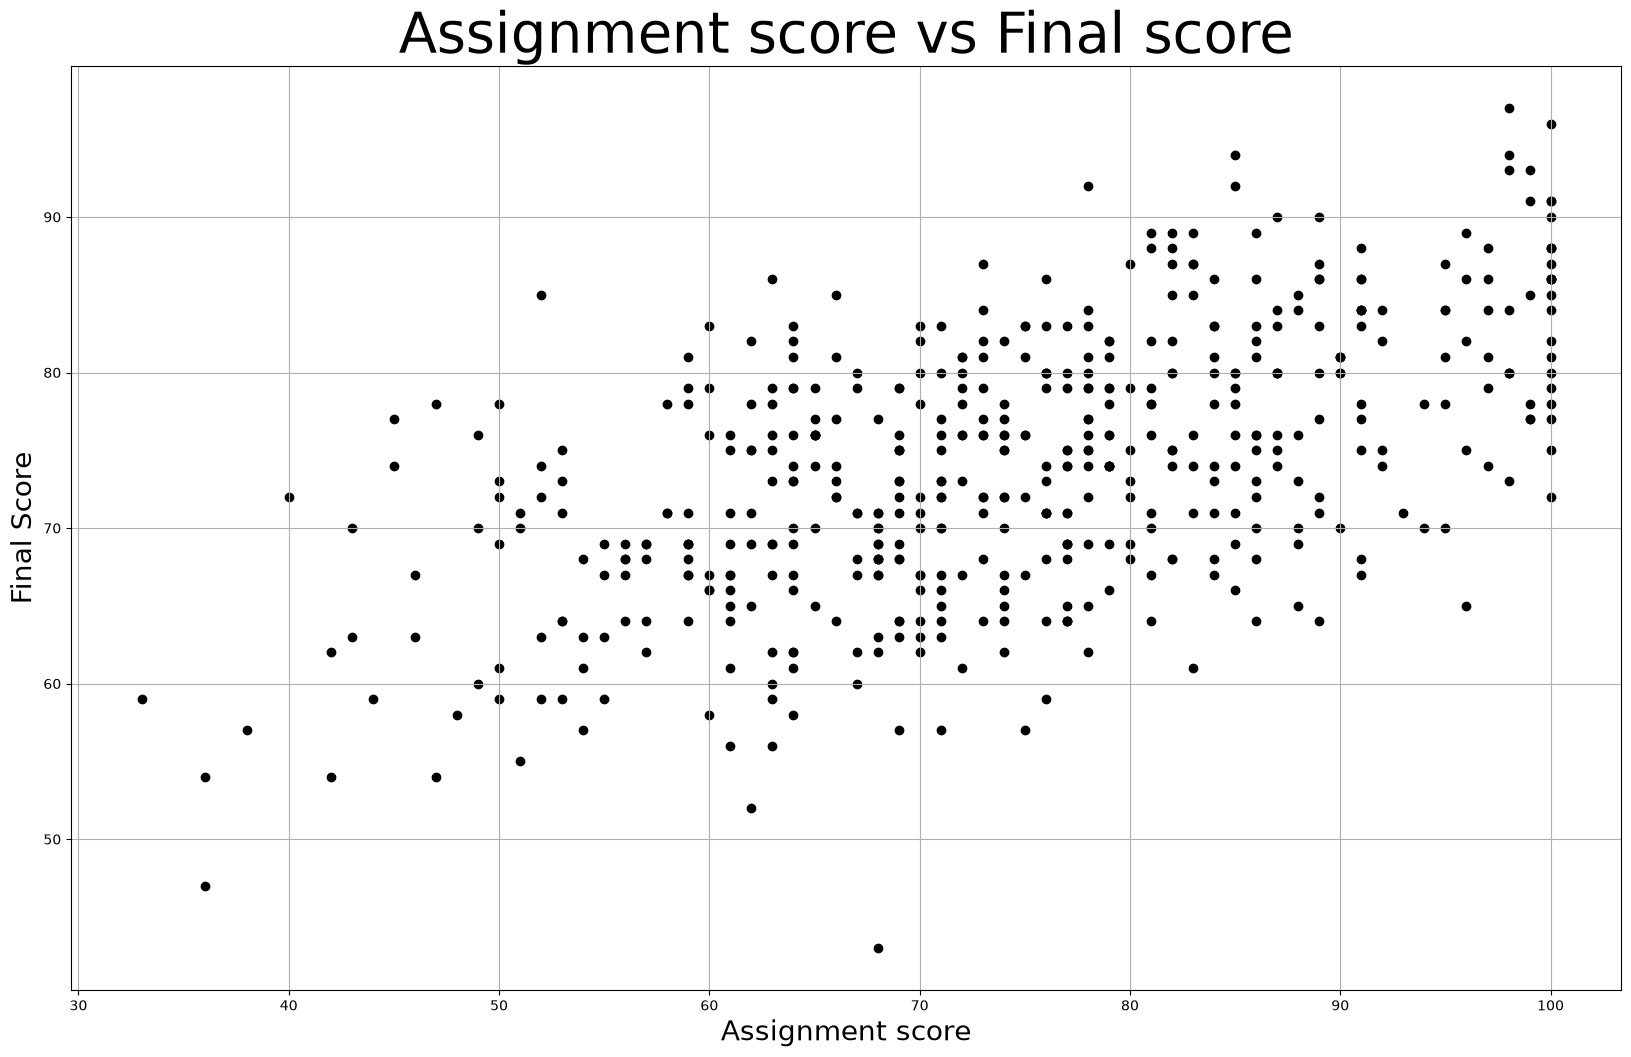

In [65]:
#6.2 Assignment score vs final score
plt.figure(figsize=(20,12))
plt.scatter(dd['AssignmentScore'],dd['FinalScore'],color='black')

plt.grid()
plt.title('Assignment score vs Final score',fontsize=40)
plt.xlabel('Assignment score',fontsize=20)
plt.ylabel('Final Score',fontsize=20)


Text(0, 0.5, 'Final Score')

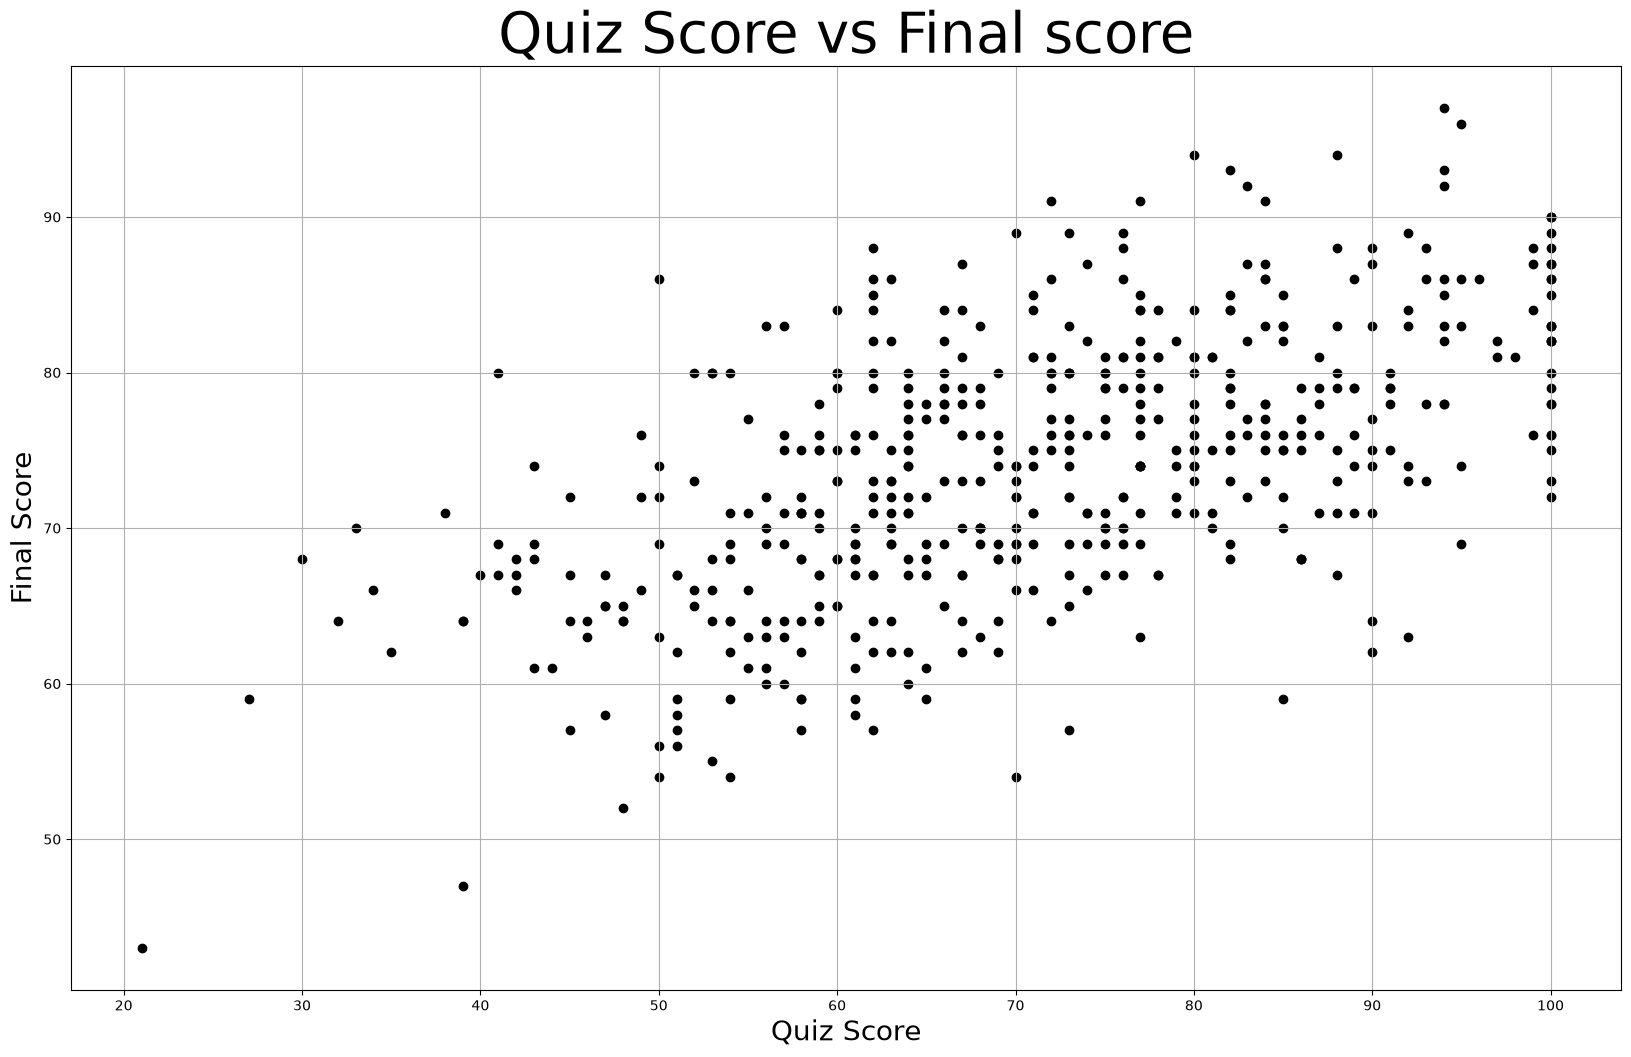

In [68]:
#6.3 quiz score vs final score
plt.figure(figsize=(20,12))
plt.scatter(dd['QuizScore'],dd['FinalScore'],color='black')

plt.grid()
plt.title('Quiz Score vs Final score',fontsize=40)
plt.xlabel('Quiz Score',fontsize=20)
plt.ylabel('Final Score',fontsize=20)


Text(0, 0.5, 'Final Score')

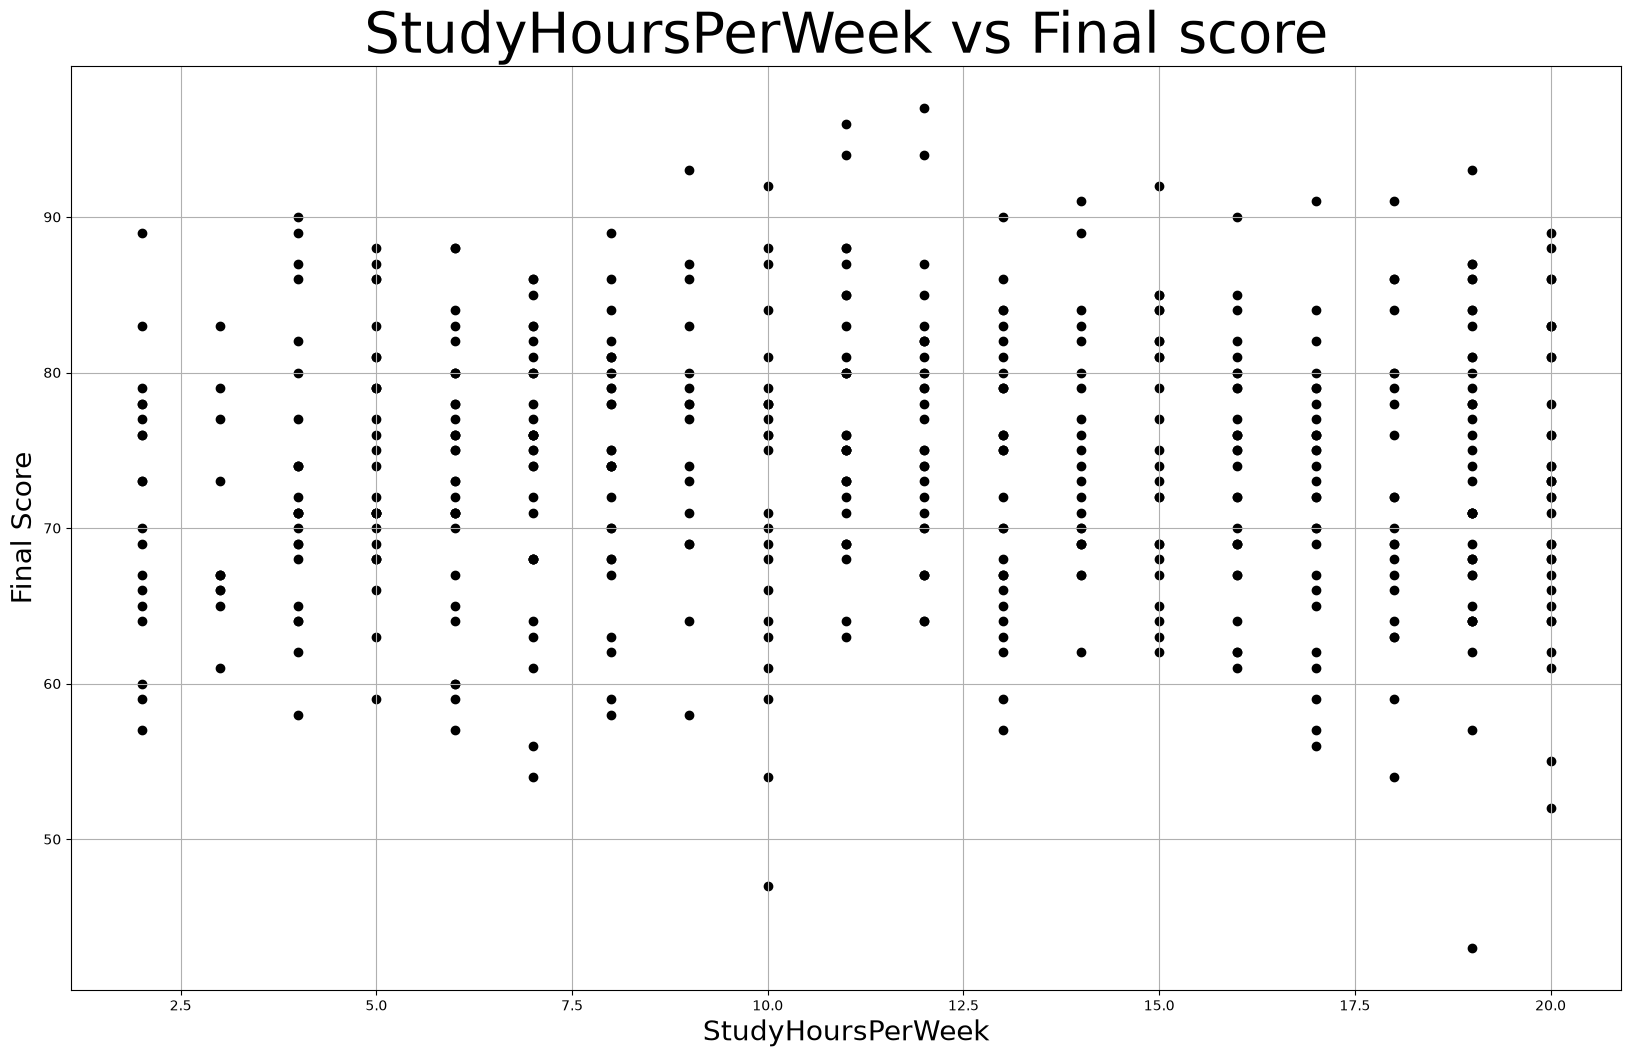

In [71]:
#6.4 StudyHoursPerWeeks final score
plt.figure(figsize=(20,12))
plt.scatter(dd['StudyHoursPerWeek'],dd['FinalScore'],color='black')

plt.grid()
plt.title('StudyHoursPerWeek vs Final score',fontsize=40)
plt.xlabel('StudyHoursPerWeek',fontsize=20)
plt.ylabel('Final Score',fontsize=20)


Text(0, 0.5, 'Final Score')

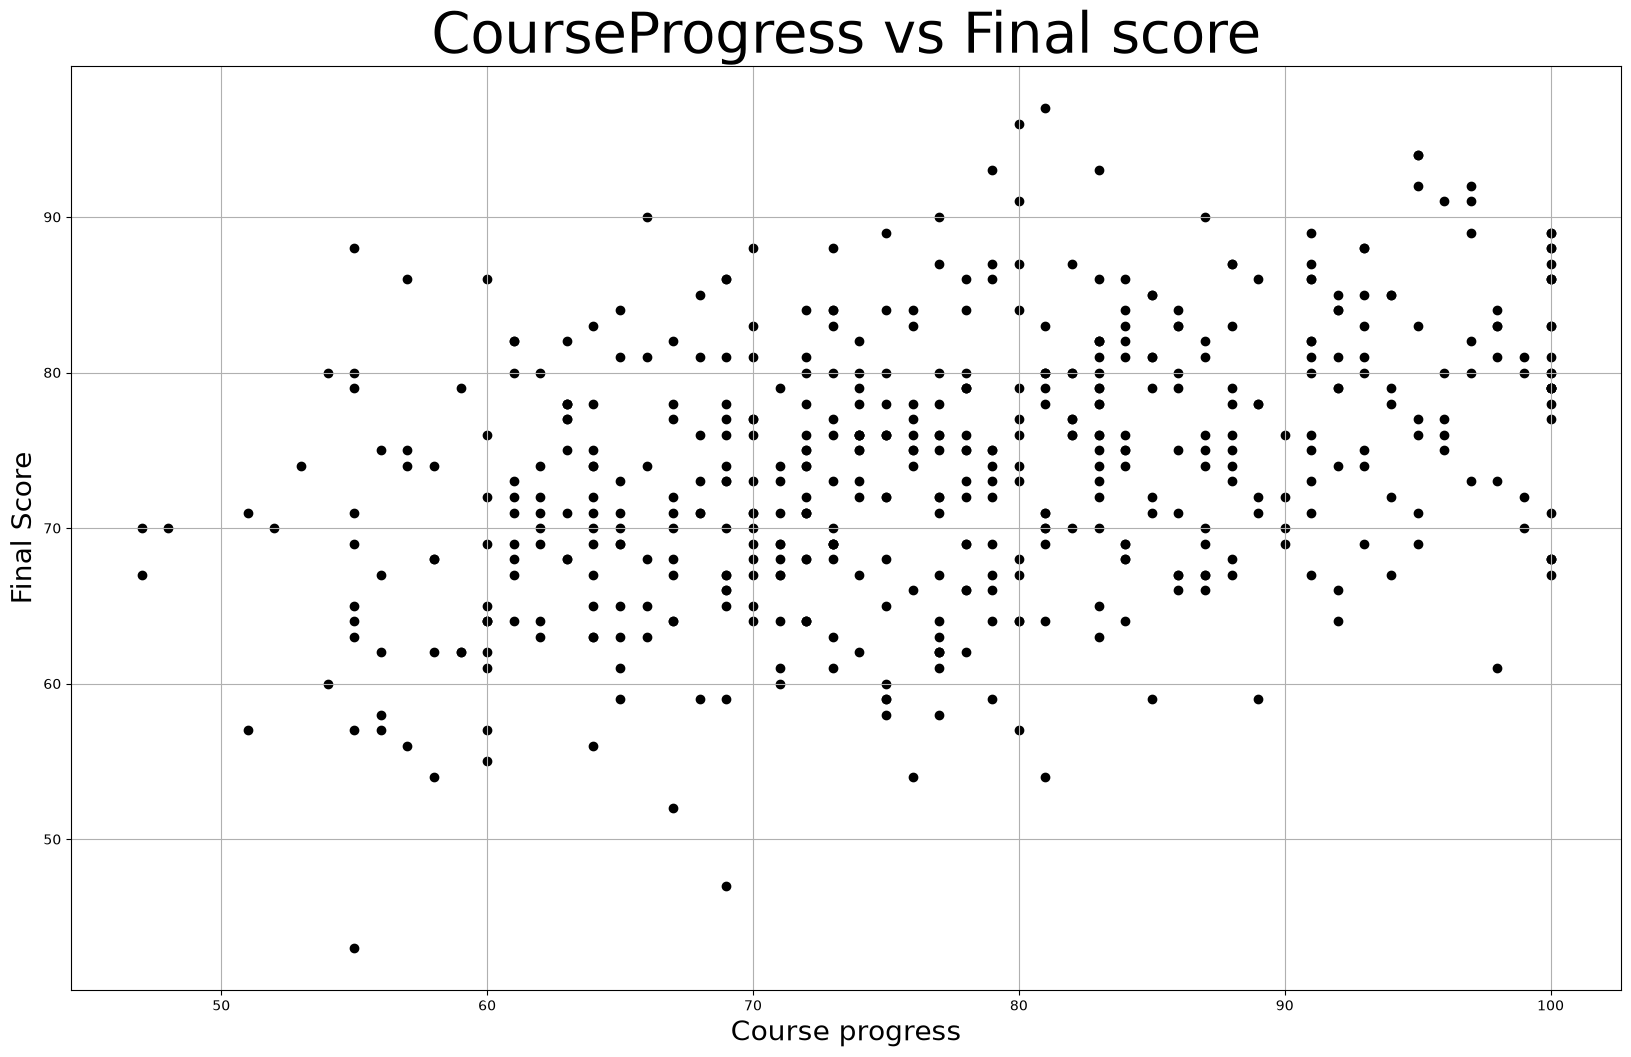

In [73]:
#6.5 Course Progress final score
plt.figure(figsize=(20,12))
plt.scatter(dd['CourseProgress'],dd['FinalScore'],color='black')

plt.grid()
plt.title('CourseProgress vs Final score',fontsize=40)
plt.xlabel('Course progress',fontsize=20)
plt.ylabel('Final Score',fontsize=20)

Text(0, 0.5, 'CourseProgress')

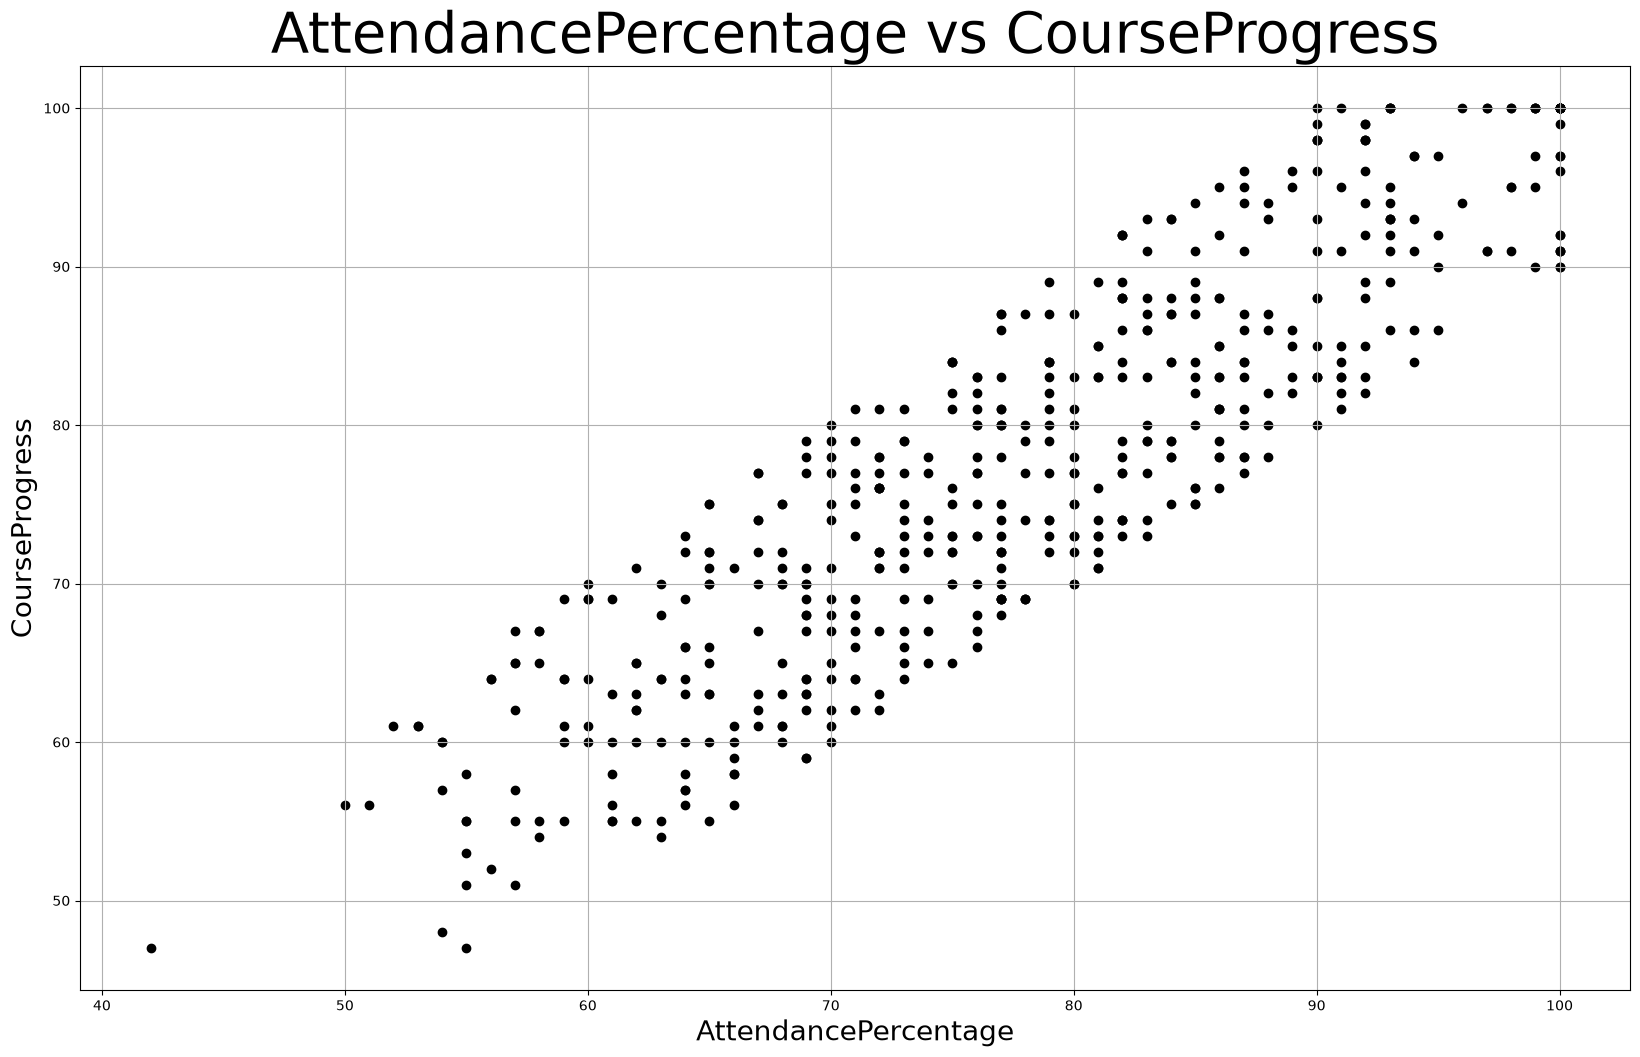

In [74]:
#6.6
plt.figure(figsize=(20,12))
plt.scatter(dd['AttendancePercentage'],dd['CourseProgress'],color='black')

plt.grid()
plt.title('AttendancePercentage vs CourseProgress',fontsize=40)
plt.xlabel('AttendancePercentage',fontsize=20)
plt.ylabel('CourseProgress',fontsize=20)